# NicheJEPA Tutorial xhk1007-kidney

- Creator: Sebastian Birk (sb75@sanger.ac.uk) Mohammad Vali Sanian (mohammad.sanian@helsinki.fi)
- Date of Creation: 30.06.2025
- Date of Last Modification: 08.07.2025 (by Mohammad Vali Sanian mohammad.sanian@helsinki.fi)

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import logging
import os
import pickle
import warnings
from typing import List, Tuple
import torch
from sklearn.metrics import silhouette_score
import gseapy as gp

import anndata as ad
import pandas as pd
import scanpy as sc
import scib_metrics
from datasets import load_from_disk
from matplotlib.colors import Normalize
import squidpy as sq
from tqdm import tqdm
from app.infer import (embed_dataset,
                       harmonize_adata,
                       tokenize_adata,
                       perturb_dataset,
                       harmonize_tokenize_embed_pipeline,
                       get_gene_embed,
                       get_average_gene_embed,
                       get_spatial_score,
                       get_emd_distance )
from nichejepa.utils.evaluation import (get_top_gene_score,
                                        get_top_gene_pairs
                                        )
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

from analysis_utils import *
from benchmarking_utils import max_overlap_plot

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [4]:
## This function takes a list of cell_ids and returns the corresponding dataset object.
def subset_by_cell_ids(dataset, cell_id_list):
    cell_id_set = set(cell_id_list)
    cell_ids = dataset['cell_id']
    indices = [i for i, cid in tqdm(enumerate(cell_ids), total=len(cell_ids), desc="Finding matching indices") if cid in cell_id_set]
    return dataset.select(indices)


### 1.2 Configure Paths

In [5]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
load_timestamp = '11062025_183320_055'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
folder_path = f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}'
model_folder_path = f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/{load_timestamp}'
read_checkpoint = 'nichejepa-ep10_0.pth.tar'

### 1.3 Define Config

In [6]:
min_cells_per_niche = 100
latent_cluster_key = 'predicted_niche'

### 1.4 Run Notebook Setup

In [7]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [8]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [9]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [10]:
#sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'
sc.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)


In [11]:
#os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
#os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
#os.makedirs(f'{benchmarking_artifacts_folder_path}/NicheJEPA', exist_ok=True)

## 2. Analysis

### 2.1 xhk1007-kidney

In [12]:
dataset_name = 'xhk1007-CV2-41b_1p'
cell_type_key = 'level_1_cell_type'
spot_size = 20
file_path = f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/CV2-KID-0-FT-1-s2.h5ad'


#### 2.1.1 Load Data

In [64]:
adata = sc.read_h5ad(file_path)
print(adata)

AnnData object with n_obs × n_vars = 26026 × 4949
    obs: 'batch', 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'outlier', 'n_genes', 'original_cell_id', 'level_1_cell_type'
    var: 'ensembl_id'
    uns: 'assay', 'batch', 'condition', 'dataset_id', 'species', 'tissue'
    obsm: 'spatial'


/tmp/ipykernel_1578663/3623556005.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


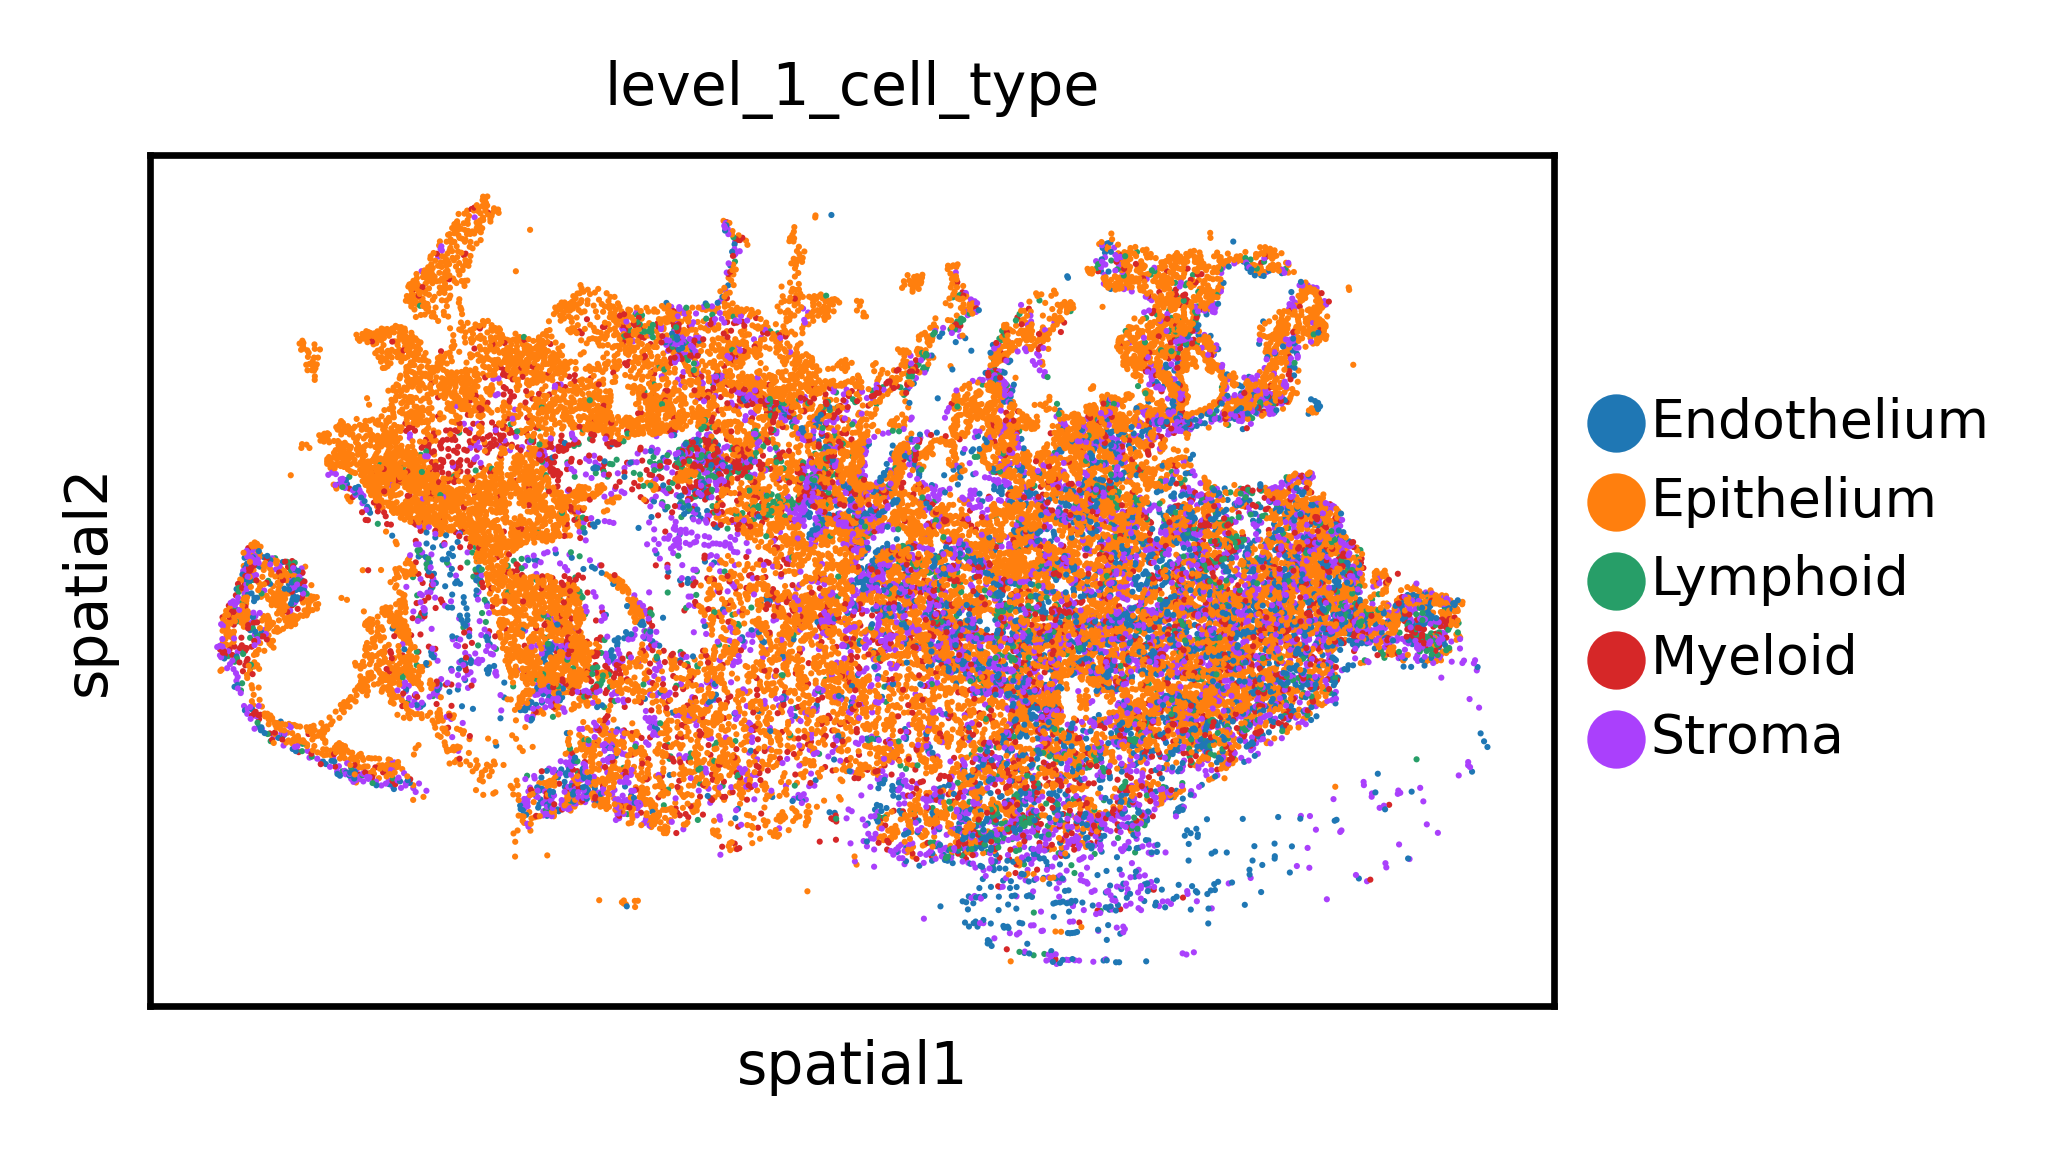

In [65]:
# Visualize data
sc.pl.spatial(adata,
              spot_size=spot_size,
              color=cell_type_key)

#### 2.1.2 Harmonize Data
If you’ve already tokenized your data, go to Load Tokenized Data and load the previously tokenized files.

In [ ]:
adata = harmonize_adata(adata)

#### 2.1.3 Tokenize Data
If you’ve already tokenized your data, go to Load Tokenized Data and load the previously tokenized files.

In [ ]:
dataset = tokenize_adata(adata,
                         model_folder_path,
                         nproc = 4,
                         processing_mode = 'parallel')

#item = dataset[0]
#print(item)

#### 2.1.4 Save Tokenize Data

In [ ]:
num_shards = 32
save_dataset_path = f"/nfs/team361/sb75/nichejepa-reproducibility/artifacts/{dataset_name}/{dataset_name}.dataset"

In [ ]:
!mkdir save_dataset_path

In [ ]:
dataset.save_to_disk(
            save_dataset_path,
            num_shards=num_shards)

#### 2.1.5 Load Tokenize Data

In [ ]:
#load_dataset_path = f'/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/{dataset_name}'
load_dataset_path = "/nfs/team361/dj17/NEMO_DJ/tokenized_dataxhk1007-CV2-41b_1p"
dataset = load_from_disk(load_dataset_path)

In [ ]:
dataset

#### 2.1.6 Embed Data

In [ ]:
emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 8
agg_excluded_tokens = None
top_k = None

In [ ]:
output_embed = embed_dataset(
    dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers)

In [ ]:
adata.obsm['cell_emb'] = output_embed['cell_emb']
adata.obsm['neighborhood_emb'] = output_embed['neighborhood_emb']

In [ ]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')
# Store the neighborhood UMAP with a custom key
adata.obsm['neighborhood_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')
# Store the cell UMAP with a custom key
adata.obsm['cell_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='cell',
           color=label)

#### 2.1.7 Niche Identification

In [ ]:
# Set dataset params
batch_key = 'batch'
emb_key = 'cell'
latent_leiden_resolution = 0.3
spot_sizes = [0.3, 30]

latent_cluster_key = f'{emb_key}_emb_leiden_res{str(latent_leiden_resolution).replace(".", "_")}'


In [ ]:
# Compute UMAP representation for (aggregated) gene embeddings
if F'{emb_key}_connectivities' not in adata.obsp.keys():
    print("Computing sc.pp.neighbors...")
    sc.pp.neighbors(adata,
                    n_neighbors=15,
                    use_rep=f'{emb_key}_emb_layer_{layer}',
                    key_added=emb_key)
if f'{emb_key}_umap' not in adata.obsm.keys():
    print("Computing sc.tl.umap...")
    sc.tl.umap(adata,
               neighbors_key=emb_key,
               key_added=f'{emb_key}_umap')


In [ ]:
sc.tl.leiden(adata,
             neighbors_key=emb_key,
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
sc.pl.spatial(
    adata,
    color=latent_cluster_key,
    spot_size=spot_size,
    save=f'{dataset_name}_{latent_cluster_key}.svg'
)

#### get summery of gene_experesion on this data

In [ ]:
def summarize_gene_expression(
    adata,
    subset_cell_ids: list,
    top_n: int = 10,
    ensembl_col: str = "ensembl_id"
):
    """
    Filter AnnData to a subset of cells, compute gene expression summaries,
    and return top expressed genes with Ensembl IDs.

    Args:
        adata (AnnData): Pre-loaded AnnData object.
        subset_cell_ids (list): List of cell IDs to filter.
        top_n (int): Number of top expressed genes to return.
        ensembl_col (str): Column in adata.var that contains Ensembl IDs.

    Returns:
        combined_counts (pd.DataFrame): Filtered cell-by-gene count matrix.
        top_gene_df (pd.DataFrame): DataFrame with top gene names and Ensembl IDs.
    """
    if 'cell_id' not in adata.obs.columns:
        raise KeyError("Expected `adata.obs` to contain a 'cell_id' column.")
    if ensembl_col not in adata.var.columns:
        raise KeyError(f"Expected `adata.var` to contain '{ensembl_col}' column.")

    # Filter to subset of cells
    mask = adata.obs['cell_id'].astype(str).isin(set(subset_cell_ids))
    filtered = adata[mask].copy()
    if filtered.n_obs == 0:
        raise ValueError("No matching cells found in the provided subset.")

    # Extract dense matrix
    matrix = filtered.X.toarray() if hasattr(filtered.X, "toarray") else filtered.X
    combined_counts = pd.DataFrame(matrix, columns=filtered.var_names, index=filtered.obs_names)

    # Compute mean expression and get top N genes
    mean_expr = combined_counts.mean(axis=0)
    top_genes = mean_expr.nlargest(top_n)

    # Map to Ensembl IDs
    var_df = adata.var.loc[top_genes.index]
    top_gene_df = pd.DataFrame({
        "gene_name": top_genes.index,
        "ensembl_id": var_df[ensembl_col].values,
        "mean_expression": top_genes.values
    })

    return combined_counts, top_gene_df


In [ ]:
combined_counts, top_gene_df = summarize_gene_expression(adata, list(adata.obs['cell_id']),top_n=1000)

#### 2.1.8 compute_emd_distance
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [ ]:
# each list should at least contain 20 gene each 
# to have score that is meaningful
# compute mmd also and add it 
cell_gene_ensembl_id = list(top_gene_df['ensembl_id'])
neighborhood_gene_ensembl_id = list(top_gene_df['ensembl_id'])  # ['all'] * len(perturbed_cell_id)


In [ ]:
output_emd_distance = get_emd_distance( dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

In [ ]:
adata.obs['emd_dist'] = output_emd_distance

In [ ]:
# 2) Normalize your data so that 0→0; 0.6→1.0
norm = Normalize(vmin=0.0, vmax=max(output_emd_distance))

# 3) Build the colormap
#cmap = make_thresholded_cmap(base_cmap="plasma", threshold=0.8)

sq.pl.spatial_scatter(
        adata,
        color='emd_dist',
        #cmap=cmap,
        norm=norm,
        shape=None,
        figsize=(10, 8),
        size=1.5,
        title=f"{dataset_name} - (EMD distance)",
)
plt.show()

#### 2.1.9 subset dataset instruction
You can use this method of subsetting dataasets in all your tasks. This is just a template for how to use it.

In [ ]:
subset_cell_ids = ['1002_batch40_0',
 '1002_batch40_1',
 '1002_batch40_2',
 '1002_batch40_3',
 '1002_batch40_4',
 '1002_batch40_5',
 '1002_batch40_6',
 '1002_batch40_7',
 '1002_batch40_8',
 '1002_batch40_9']


In [ ]:
dataset_subset = subset_by_cell_ids(dataset, subset_cell_ids)

In [ ]:
dataset_subset

#### 2.1.10 get_gene_representation
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [ ]:
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 8

In [ ]:
cell_gene_ensembl_id = ['ENSG00000104419', 'ENSG00000130402']
neighborhood_gene_ensembl_id = ['ENSG00000104419','ENSG00000130402'] # ['all'] * len(perturbed_cell_id)

In [ ]:
output_gene_embed = get_gene_embed( dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

In [ ]:
for gene_ens in output_gene_embed.keys():
    adata.obsm[gene_ens] = output_gene_embed[gene_ens]

#### 2.1.11 get_average_gene_representation
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [ ]:
list(adata.var['ensembl_id'])

In [ ]:
cell_gene_ensembl_id = list(top_gene_df['ensembl_id'])
neighborhood_gene_ensembl_id = list(top_gene_df['ensembl_id']) # ['all'] * len(perturbed_cell_id)

cell_gene_ensembl_id = list(adata.var['ensembl_id'])
neighborhood_gene_ensembl_id = list(adata.var['ensembl_id'])

In [ ]:
output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

In [ ]:
adata.uns['cell_gene_emb_average_per_data'] = output_average_gene_embed['cell_gene_emb_average_per_data']
adata.uns['cell_gene_emb_counts_per_data'] = output_average_gene_embed['cell_gene_emb_counts_per_data']
adata.uns['neighborhood_gene_emb_average_per_data'] = output_average_gene_embed['neighborhood_gene_emb_average_per_data']
adata.uns['neighborhood_gene_emb_counts_per_data'] = output_average_gene_embed['neighborhood_gene_emb_counts_per_data']

In [ ]:
adata.uns['cell_gene_emb_average_per_data']

In [ ]:
# 1) You can choose any of the embeddings, which could be either a cell or a neighborhood.
gene_emb_name = 'neighborhood_gene_emb_average_per_data'
gene_emb_name = 'cell_gene_emb_average_per_data'


In [ ]:
gene_emb_name

In [ ]:
gene_emb = np.array(adata.uns[gene_emb_name])  # (n_genes, emb_dim)
gene_ids =  np.array(cell_gene_ensembl_id,  dtype=str)                  # (n_genes,)

# 2) Remove any gene rows containing NaNs
mask = ~np.isnan(gene_emb).any(axis=1)
gene_emb_clean = gene_emb[mask]
gene_ids_clean = gene_ids[mask]

# 3) Build a small AnnData where each "obs" is one gene
adata_genes = ad.AnnData(
    X=gene_emb_clean,
    obs=pd.DataFrame({'gene_id': gene_ids_clean})
)
adata_genes.obs_names = gene_ids_clean.astype(str)

# 4) Compute a neighborhood graph on the embeddings
sc.pp.neighbors(
    adata_genes,
    use_rep='X',
    n_neighbors=15,
    metric='euclidean'
)

# 5) Run UMAP
sc.tl.umap(
    adata_genes,
    #min_dist=0.5,
    #spread=1.0
)


# 7) (Optional) Quick plot
sc.pl.umap(
    adata_genes,
    title='Gene embedding UMAP',
    show=True
)


In [ ]:
sc.tl.pca(adata_genes, n_comps=2, use_highly_variable=False, svd_solver='arpack')

sc.pl.pca(
    adata_genes,
    components=['1,2'],   # plot PC1 vs PC2
    color=None,
    title='Gene embeddings PCA (PC1 vs PC2)',
    show=True
)


In [ ]:
# Store results here
results = []

# Define parameters
knn_values = [5, 10, 15, 20]
resolutions = np.arange(0.1, 1.1, 0.1)  # 0.1 to 1.0

# Loop over each KNN and resolution combination
for knn in knn_values:
    sc.pp.neighbors(adata_genes, n_neighbors=knn, use_rep='X')  # use 'X' or other embedding like 'X_pca'
    
    for res in resolutions:
        # Run Leiden clustering
        sc.tl.leiden(adata_genes, resolution=res, key_added='leiden_tmp')
        
        # Compute silhouette score
        labels = adata_genes.obs['leiden_tmp']
        if len(np.unique(labels)) < 2:
            score = np.nan  # silhouette score not defined for 1 cluster
        else:
            score = silhouette_score(adata_genes.obsm['X_pca'], labels)  # you can change to 'X' if no PCA
        
        # Store results
        results.append({
            'knn': knn,
            'resolution': round(res, 2),
            'silhouette_score': score
        })

# Convert results to DataFrame
df = pd.DataFrame(results)
df['combo'] = df['knn'].astype(str) + '_k_' + df['resolution'].astype(str)

# Plot
plt.figure(figsize=(12, 6))
df_sorted = df.sort_values('silhouette_score', ascending=False)
plt.bar(df_sorted['combo'], df_sorted['silhouette_score'], color='skyblue')
plt.xticks(rotation=90)
plt.ylabel("Silhouette Score")
plt.xlabel("KNN_Resolution Combination")
plt.title("Silhouette Score for Different KNN and Leiden Resolution Settings")
plt.tight_layout()
plt.show()


In [ ]:
sc.pp.neighbors(adata_genes,n_neighbors=20)
sc.tl.leiden(adata_genes,resolution=0.2,key_added='r9')

In [ ]:
sc.pl.umap(adata_genes,color='r9',frameon=False)

In [ ]:
id_to_name = {ensg: name for name, ensg in adata.var['ensembl_id'].items()}

In [ ]:
interesting_group = '0'
ens_interesting_group = list(adata_genes.obs[adata_genes.obs['r9']==interesting_group]['gene_id'])

In [ ]:
genes  = [ id_to_name.get(ensg, "UNKNOWN") for ensg in ens_interesting_group]

In [ ]:
len(genes)

In [ ]:
# 2) Your input gene list
# 3) Call gseapy.enrichr
#    You can choose any Enrichr library; here are some examples:
# I should create a mapping from gene_id to ens
# from 110 release
libraries = [
    'KEGG_2019_Human',
    'GO_Biological_Process_2021',
    'Reactome_Pathways_2024',
    'MSigDB_Hallmark_2020'
]

# Run ORA for each library
results = {}
for lib in libraries:
    enr = gp.enrichr(
        gene_list = genes,
        gene_sets  = lib,
        outdir     = None,        # don't write files
        cutoff     = 0.05,         # only show terms with adjusted p < 0.05
    )
    # enr.results is a pandas DataFrame
    results[lib] = enr.results

# 4) Inspect top enriched terms for each library
for lib, df in results.items():
    print(f"\n=== Top 5 terms in {lib} ===")
    display(df[['Term','Adjusted P-value','Combined Score']].head(20))


In [ ]:
print(genes)

#### 2.1.12 compute_spatial_score
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [ ]:
adata.var

In [ ]:
# for out put of get_top_gene_score be correct both cell_gene_ensembl_id and 
# neighborhood_gene_ensembl_id should have same size and same order
cell_gene_ensembl_id =  list(top_gene_df['ensembl_id']) 
neighborhood_gene_ensembl_id =  list(top_gene_df['ensembl_id'])  # ['all'] * len(perturbed_cell_id)

In [ ]:
output_cosine_sim_score = get_spatial_score(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

In [ ]:
gene_pair_score = output_cosine_sim_score['cos_sim_neighborhood'] / output_cosine_sim_score['cos_sim_cell']

In [ ]:
gene_pair_score

In [ ]:
output_cosine_sim_score['cell_count_neighborhood']

In [ ]:
df_gene_scores = get_top_gene_score(gene_pair_score, 
                                    cell_gene_ensembl_id, 
                                    gene_df=adata.var, 
                                    gene_counts= output_cosine_sim_score['cell_count_neighborhood'],
                                    min_count = 20)

In [ ]:
df_gene_scores.sort_values(by='gene_score', ascending=False)

In [ ]:
df_gene_pairs_score = get_top_gene_pairs(
    torch.from_numpy(gene_pair_score),
    count_cell=torch.from_numpy(output_cosine_sim_score['cell_count_neighborhood']),
    count_neb=torch.from_numpy(output_cosine_sim_score['cell_count_cell']),
    cos_sim_cell=torch.from_numpy(output_cosine_sim_score['cell_count_cell']),
    cos_sim_neb=torch.from_numpy(output_cosine_sim_score['cos_sim_neighborhood']),
    gene_df=adata.var,
    cell_gene_ids=cell_gene_ensembl_id,
    neighborhood_gene_ids=neighborhood_gene_ensembl_id,
    min_count=20,
    sim_thresh=0.0,
    k=500
)


In [ ]:
df_gene_pairs_score

#### 2.1.13 Perturbed Data

##### 2.1.13.1 Nivolumab

In [ ]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='nivolumab_perturbed_neighborhood_emb',
                key_added='nivolumab_perturbed_neighborhood')
sc.tl.umap(adata,
           neighbors_key='nivolumab_perturbed_neighborhood')
# Store the neighborhood UMAP with a custom key
adata.obsm['nivolumab_perturbed_neighborhood_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='nivolumab_perturbed_neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='nivolumab_perturbed_cell_emb',
                key_added='nivolumab_perturbed_cell')
sc.tl.umap(adata,
           neighbors_key='nivolumab_perturbed_cell')
# Store the cell UMAP with a custom key
adata.obsm['nivolumab_perturbed_cell_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='nivolumab_perturbed_cell',
           color=label)

In [66]:
emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 8
agg_excluded_tokens = None
top_k = None

In [67]:
# Define genes of interest
target_genes = ['ABCC9', 'ABCG2', 'ACE', 'ACHE', 'ACKR3', 'ACOD1', 'ACTL7A', 'ACVRL1', 'ADAM12', 'ADAM33', 'ADAMTS1', 'ADAMTS12', 'ADAMTS19', 'ADAMTS2', 'ADAMTS4', 'ADAMTS5', 'ADAMTSL3', 'ADCYAP1R1', 'ADGRA2', 'ADGRD1', 'ADGRL1', 'ADGRL4', 'ADRA1A', 'ADRA1B', 'ADRA1D', 'ADRA2A', 'ADRB3', 'AFAP1L2', 'AGTR1', 'AGXT', 'AIRE', 'AJAP1', 'ANGPT1', 'ANGPT2', 'ANGPTL2', 'ANO1', 'ANO3', 'AOC3', 'APCDD1', 'APLNR', 'APOL3', 'ARC', 'ARHGEF7', 'ARRB1', 'ART4', 'ASPM', 'ASPN', 'ATOH8', 'ATP6V1B1', 'AUNIP', 'AURKB', 'AVPR1A', 'AXL', 'BAALC', 'BAG2', 'BATF3', 'BCAM', 'BCL3', 'BCL6B', 'BDKRB2', 'BFSP1', 'BID', 'BIK', 'BMP2', 'BMP4', 'BMP5', 'BMP6', 'BMP8A', 'BMPR1B', 'BRSK2', 'BVES', 'C1QL3', 'C1QTNF1', 'C1QTNF9', 'CA4', 'CABP4', 'CABYR', 'CACNA1C', 'CACNA1H', 'CALCRL', 'CARD8', 'CASQ2', 'CAVIN2', 'CAVIN3', 'CBARP', 'CBLN1', 'CBLN4', 'CCDC102B', 'CCDC33', 'CCDC80', 'CCK', 'CCL11', 'CCL14', 'CCL16', 'CCL19', 'CCL23', 'CCN1', 'CCN2', 'CCN3', 'CCN4', 'CCNB3', 'CCND2', 'CD200', 'CD248', 'CD276', 'CD34', 'CD36', 'CD79B', 'CD93', 'CDA', 'CDH11', 'CDH13', 'CDH3', 'CDH5', 'CDK17', 'CDKN2B', 'CDKN3', 'CDX1', 'CEACAM1', 'CENPV', 'CEP55', 'CETP', 'CHODL', 'CHRM3', 'CILP2', 'CKAP4', 'CLDN5', 'CLEC14A', 'CMTM8', 'CNR1', 'CNRIP1', 'CNST', 'CNTN2', 'COL10A1', 'COL11A1', 'COL25A1', 'COL4A2', 'COL5A1', 'COL5A2', 'COL7A1', 'COMP', 'CORIN', 'CPA6', 'CPLX3', 'CPXM2', 'CRHR2', 'CSF1', 'CSF3', 'CSPG4', 'CSRP1', 'CST2', 'CST4', 'CTHRC1', 'CTNNAL1', 'CTSK', 'CX3CL1', 'CXCL2', 'DACH1', 'DBN1', 'DDX43', 'DKK1', 'DKK3', 'DLG4', 'DLK1', 'DLL1', 'DLL4', 'DMD', 'DMPK', 'DNAH2', 'DNASE1L3', 'DOCK9', 'DRC1', 'DRD1', 'DUOX2', 'DUOXA1', 'DUSP5', 'DUSP6', 'EBF1', 'EBF2', 'ECE1', 'ECRG4', 'EDIL3', 'EDN1', 'EDNRA', 'EDNRB', 'EFNB2', 'EFR3B', 'EFS', 'EGFL7', 'EGR2', 'EGR3', 'ELFN1', 'ELK3', 'ELN', 'EMP1', 'EMP2', 'EN1', 'ENG', 'ENKUR', 'ENOX1', 'ENTPD1', 'EPHA2', 'EPHA3', 'EPHA4', 'EPHB4', 'ERFE', 'ERG', 'ESM1', 'ETS1', 'EYA4', 'F2R', 'F2RL3', 'F8', 'FAM107A', 'FAP', 'FAT3', 'FBLN2', 'FBLN5', 'FETUB', 'FEZ1', 'FGF1', 'FGF13', 'FHL2', 'FHL3', 'FILIP1L', 'FLT4', 'FMN2', 'FMO3', 'FOLH1', 'FOSL1', 'FOXB1', 'FOXC1', 'FOXC2', 'FOXD2', 'FOXF1', 'FOXG1', 'FOXL2', 'FRMD6', 'FSCN1', 'FST', 'FYN', 'FZD10', 'GABRA3', 'GABRA6', 'GABRD', 'GABRQ', 'GAL', 'GALR1', 'GAP43', 'GAS2L1', 'GATA2', 'GATA6', 'GBX2', 'GDF11', 'GDF5', 'GDF6', 'GDF7', 'GDNF', 'GIMAP4', 'GIMAP5', 'GIMAP8', 'GJA1', 'GJA5', 'GJC1', 'GLI1', 'GLI2', 'GLI3', 'GLT8D2', 'GNAI1', 'GNAT3', 'GPR158', 'GPR26', 'GPR3', 'GPR4', 'GPR63', 'GPRC5B', 'GREB1L', 'GRIA1', 'GRID1', 'GRIK3', 'GRIK5', 'GRIN2C', 'GRK5', 'GTF2A1L', 'GUCY1A2', 'GYPB', 'HAS2', 'HCN4', 'HCRTR1', 'HDAC9', 'HES1', 'HES4', 'HEY1', 'HGF', 'HHEX', 'HLX', 'HMCN1', 'HMGA2', 'HMX2', 'HOPX', 'HOXA11', 'HOXA9', 'HOXB5', 'HOXB6', 'HOXC13', 'HOXD10', 'HOXD9', 'HPSE2', 'HRH1', 'HS3ST3A1', 'HSD11B1', 'HSD17B2', 'HSD17B6', 'HSPB3', 'HSPG2', 'HTR1A', 'HTR1B', 'HTR1E', 'HTR2B', 'ICA1', 'ICAM2', 'ID4', 'IDO1', 'IFITM1', 'IFNA2', 'IGF2', 'IGFBP2', 'IL12A', 'IL13RA2', 'IL15RA', 'IL17B', 'IL26', 'IL33', 'IL3RA', 'IL4R', 'IL6', 'INHBA', 'INHBB', 'INMT', 'INPP4B', 'INSM1', 'IQSEC1', 'IRGM', 'IRX1', 'ITGA1', 'ITGA5', 'ITGB1BP2', 'ITGB3', 'ITM2A', 'JAG1', 'JAM2', 'JAM3', 'KCNA5', 'KCNB1', 'KCNC4', 'KCNF1', 'KCNH1', 'KCNH4', 'KCNJ12', 'KCNJ2', 'KCNJ8', 'KCNJ9', 'KCNK12', 'KCNK6', 'KCNMB1', 'KCNN3', 'KCNQ1', 'KCNQ4', 'KCNT1', 'KCNT2', 'KCTD10', 'KDR', 'KIF20A', 'KIT', 'KITLG', 'KLF12', 'KLHL14', 'LAMC1', 'LBH', 'LDB3', 'LDLR', 'LGALSL', 'LIFR', 'LIPE', 'LMO2', 'LMX1B', 'LOXL2', 'LPL', 'LRRC15', 'LRRC3', 'LRRC32', 'LRTM1', 'LTBP1', 'LTBP2', 'LZTS1', 'MAB21L1', 'MAGI1', 'MAGI3', 'MALL', 'MAP1A', 'MAP1B', 'MAP1LC3A', 'MAP2', 'MAP3K20', 'MAP3K7CL', 'MAP4K2', 'MAPK11', 'MAPK12', 'MC3R', 'MCAM', 'MCHR2', 'MECOM', 'MEF2C', 'MEIS1', 'MEIS2', 'MEIS3', 'MFGE8', 'MICAL2', 'MKX', 'MLF1', 'MMP11', 'MMP21', 'MMP9', 'MMRN2', 'MNX1', 'MPPED2', 'MRAP2', 'MRC2', 'MRTFB', 'MSI1', 'MTNR1A', 'MYH10', 'MYLIP', 'MYLK', 'MYLK2', 'MYO18B', 'MYO1B', 'MYO1C', 'NAP1L3', 'NAV1', 'NAV2', 'NBL1', 'NDRG2', 'NDRG4', 'NECTIN1', 'NEDD4', 'NEIL3', 'NES', 'NETO1', 'NEUROD2', 'NEXN', 'NFATC4', 'NGF', 'NGFR', 'NKX2-3', 'NLRC5', 'NOD1', 'NOL4L', 'NOS2', 'NOS3', 'NOSTRIN', 'NOTCH1', 'NOTCH3', 'NOTCH4', 'NPAS4', 'NPFFR2', 'NPPC', 'NPR1', 'NPY1R', 'NR5A2', 'NRK', 'NRN1', 'NRP2', 'NT5DC2', 'NT5DC3', 'NTF3', 'NTN4', 'NTS', 'NXN', 'OIT3', 'OLFM1', 'OLFM2', 'OSR2', 'P2RY1', 'P2RY14', 'P4HA3', 'PALMD', 'PAPPA', 'PARM1', 'PAWR', 'PCBP3', 'PCDH17', 'PCDH18', 'PCSK1', 'PDE2A', 'PDE3A', 'PDE5A', 'PDGFA', 'PDGFB', 'PDGFD', 'PDGFRA', 'PDGFRB', 'PDLIM2', 'PDLIM4', 'PDZD4', 'PEA15', 'PECAM1', 'PGR', 'PHF21B', 'PIEZO1', 'PIEZO2', 'PIMREG', 'PIWIL1', 'PKD1L1', 'PKNOX2', 'PLA2G5', 'PLAT', 'PLD1', 'PLN', 'PLS3', 'PLVAP', 'PLXDC1', 'PML', 'PODXL', 'PON1', 'POSTN', 'POTEF', 'PPARG', 'PPP1R16B', 'PPP1R1C', 'PRDM6', 'PRKCH', 'PROX1', 'PRPH2', 'PRRG2', 'PRRT2', 'PRRX1', 'PRTN3', 'PTCH1', 'PTGES', 'PTGIR', 'PTGIS', 'PTP4A3', 'PTPN5', 'PWWP3A', 'PYGM', 'PZP', 'RAPGEF3', 'RAPGEF5', 'RARB', 'RASD1', 'RASD2', 'RBM20', 'RBMS1', 'RBMS3', 'RCAN2', 'RDM1', 'RECK', 'RET', 'RFTN1', 'RGS4', 'RGS5', 'RNF112', 'ROBO4', 'RSPO3', 'RUNX1T1', 'RXFP1', 'RXFP3', 'S1PR1', 'S1PR3', 'S1PR5', 'SASH1', 'SCNN1G', 'SCRN1', 'SELE', 'SELP', 'SEMA3A', 'SEMA3F', 'SEPTIN5', 'SERPINE1', 'SH2D3C', 'SH3TC2', 'SHANK3', 'SHROOM1', 'SIM2', 'SIX1', 'SLC12A2', 'SLC17A7', 'SLC1A2', 'SLC25A31', 'SLC2A4', 'SLC35G2', 'SLC6A1', 'SLC6A9', 'SLC9A1', 'SLCO1C1', 'SLIT3', 'SMAD1', 'SMC4', 'SMOC2', 'SMTN', 'SMURF1', 'SNAI1', 'SNAI2', 'SOX11', 'SOX17', 'SOX18', 'SOX21', 'SOX5', 'SOX8', 'SPAAR', 'SPATA16', 'SPECC1', 'SPHK1', 'SPRY2', 'SRF', 'SRPX', 'SSTR2', 'SSX1', 'STEAP4', 'STX1A', 'SULF1', 'SV2C', 'SVEP1', 'SYNPO2', 'TACR1', 'TAFA5', 'TAL1', 'TAL2', 'TBX15', 'TBX2', 'TBX3', 'TBX4', 'TBXA2R', 'TCERG1L', 'TCF21', 'TCF4', 'TCIM', 'TDO2', 'TECPR1', 'TEDC1', 'TEK', 'TEKT4', 'TENT5B', 'TFAP2A', 'TGFB1I1', 'TGFB2', 'TGFB3', 'TGFBR2', 'TGM6', 'THBS2', 'THEM6', 'TIAM1', 'TIE1', 'TIMP2', 'TINAGL1', 'TJP1', 'TLE6', 'TNC', 'TNF', 'TNR', 'TNXB', 'TOX2', 'TP63', 'TPPP3', 'TPTE', 'TRIB2', 'TRPC3', 'TRPC4', 'TRPC6', 'TRPM1', 'TRPM6', 'TSPAN13', 'TSPAN7', 'TSPY1', 'TSPYL5', 'TUBB6', 'TWIST1', 'TWIST2', 'TYRO3', 'ULBP2', 'UNC13A', 'UNC5A', 'VCL', 'VEGFC', 'VGLL3', 'VHL', 'VIP', 'VIPR1', 'WFDC1', 'XIRP1', 'ZEB1', 'ZNF469', 'ZYX']
emt_genes = ['SNAI1', 'SNAI2', 'TWIST1', 'TWIST2', 'ZEB1']
housekeeping_genes = ['HPRT', 'GAPDH', 'TUBB']

# Load gene name to ensembl ID dictionary
gene_name_to_ensembl_id_dict_path = '/nfs/team361/sb75/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl'
with open(gene_name_to_ensembl_id_dict_path, 'rb') as f:
    gene_name_to_ensembl_id_dict = pickle.load(f)

# Load tokenized (unperturbed data)
save_dataset_path = f"/nfs/team361/sb75/nichejepa-reproducibility/artifacts/{dataset_name}/{dataset_name}.dataset"
dataset = load_from_disk(save_dataset_path)

In [68]:
pdcd1_expr = adata[:, 'PDCD1'].X

In [69]:
import numpy as np
from scipy.sparse import issparse

pdcd1_expr = adata[:, 'PDCD1'].X
if issparse(pdcd1_expr):
    pdcd1_expr = pdcd1_expr.toarray().flatten()
else:
    pdcd1_expr = np.asarray(pdcd1_expr).flatten()

In [70]:
expressed_mask = pdcd1_expr > 0
expressed_indices = np.where(expressed_mask)[0]

In [78]:
cell_ids = adata.obs['cell_id'][expressed_indices].tolist()

/tmp/ipykernel_1578663/2179125230.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  cell_ids = adata.obs['cell_id'][expressed_indices].tolist()


In [83]:
filtered_dataset = dataset.filter(
    lambda example: example['cell_id'] in cell_ids)

In [184]:
filtered_dataset['gene_expr'][65]

tensor([4.3820, 3.7377, 3.4657,  ..., 1.0986, 1.0986, 1.0986])

In [95]:
gene_tokens = filtered_dataset['gene_tokens']
gene_expr = filtered_dataset['gene_expr']

In [146]:
gene_tokens[20]

tensor([ 5272, 16999,  2359,  ..., 10286, 12435,  1859])

In [170]:
adata[expressed_indices, 'PDCD1'].X.toarray()[33]

array([2])

In [171]:
gene_expr[33]

tensor([2.5649, 2.5649, 2.3979,  ..., 0.6931, 0.6931, 0.6931])

In [172]:
[torch.any(tokens == 15995) for tokens in gene_tokens][33]

tensor(True)

In [89]:
token_dict['ENSG00000188389']

15995

In [23]:
### Retrieve gene embeddings: unperturbed ###

for experiment_name in ['unperturbed_emt_genes']: # ['unperturbed_target_genes', 'unperturbed_target_genes_subset', 'unperturbed_housekeeping_genes']

    if experiment_name == 'unperturbed_target_genes':
        genes = target_genes
    elif experiment_name == 'unperturbed_emt_genes':
        genes = emt_genes
    elif experiment_name == 'unperturbed_housekeeping_genes':
        genes = housekeeping_genes
    
    ensembl_ids = [gene_name_to_ensembl_id_dict.get(gene, '') for gene in genes]
    ensembl_ids = [gene for gene in ensembl_ids if gene != '']
    
    # Get gene embeddings
    output_gene_embed = get_gene_embed(
        dataset=filtered_dataset,
        model_folder_path=model_folder_path,
        emb_layer=emb_layer,
        batch_size=batch_size,
        pin_memory=pin_memory,
        num_workers=num_workers,
        cell_gene_ensembl_id=ensembl_ids,
        neighborhood_gene_ensembl_id=ensembl_ids
    )
    
    # Save gene embeddings
    with open(f'{folder_path}/output_gene_embed_{experiment_name}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'wb') as f:
        pickle.dump(output_gene_embed, f)

STEP 1: LOADING CONFIG...
STEP 2: GETTING GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1516: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
2it [00:04,  2.04s/it]


In [61]:
filtered_dataset['gene_expr'][1].sum()

tensor(3275.0215)

In [62]:
perturbed_dataset['gene_expr'][1].sum()

tensor(3275.0215)

In [24]:
### Retrieve gene embeddings: knockout PDCD1 (ENSG00000188389) - mimicking nivolumab therapy ###

for experiment_name in ['nivolumab_emt_genes']: # ['nivolumab_target_genes', 'nivolumab_emt_genes', 'nivolumab_housekeeping_genes']

    if experiment_name == 'nivolumab_target_genes':
        genes = target_genes
    elif experiment_name == 'nivolumab_emt_genes':
        genes = emt_genes
    elif experiment_name == 'nivolumab_housekeeping_genes':
        genes = housekeeping_genes

    perturbed_cell_id = adata.obs['cell_id'].tolist() * 2
    perturbed_ensembl_id = ['ENSG00000188389'] * len(perturbed_cell_id)
    perturbation_target = ['neighborhood'] * int(len(perturbed_cell_id) / 2) + ['cell'] * int(len(perturbed_cell_id) / 2)
    perturbation_type = ['knockout'] * len(perturbed_cell_id)
    foldchange = [np.nan] * len(perturbed_cell_id)
    
    perturb_df =  pd.DataFrame({
        'perturbed_cell_id': perturbed_cell_id,
        'perturbed_ensembl_id': perturbed_ensembl_id,
        'perturbation_target': perturbation_target,
        'perturbation_type': perturbation_type, 
        'foldchange': foldchange
    })
    
    perturbed_dataset = perturb_dataset(
        dataset=filtered_dataset,
        perturb_df=perturb_df,
        model_folder_path=model_folder_path,
        nproc=1,
        batch_size=1000)
    
    ensembl_ids = [gene_name_to_ensembl_id_dict.get(gene, '') for gene in genes]
    ensembl_ids = [gene for gene in ensembl_ids if gene != '']
    
    # Get gene embeddings
    perturbed_output_gene_embed = get_gene_embed(
        dataset=perturbed_dataset,
        model_folder_path=model_folder_path,
        emb_layer=emb_layer,
        batch_size=batch_size,
        pin_memory=pin_memory,
        num_workers=num_workers,
        cell_gene_ensembl_id=ensembl_ids,
        neighborhood_gene_ensembl_id=ensembl_ids
    )
    
    # Save output_gene_embed dict
    with open(f'{folder_path}/output_gene_embed_{experiment_name}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'wb') as f:
        pickle.dump(perturbed_output_gene_embed, f)

Map: 100%|████████████████████████████████████████████████████████████████| 189/189 [00:00<00:00, 225.10 examples/s]


STEP 1: LOADING CONFIG...
STEP 2: GETTING GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1516: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
2it [00:03,  1.60s/it]


In [27]:
f'{folder_path}/output_gene_embed_{experiment_name}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl'

'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_80m/11062025_183320_055/output_gene_embed_nivolumab_emt_genes_ep10_0.pkl'

In [28]:
datasets_folder_path = '/nfs/team361/sb75/DATASETS' # '/lustre/scratch126/cellgen/team361/DATASETS'
token_dict_path = f'{datasets_folder_path}/tokenizer/token_dictionary_homo_sapiens.pkl'

# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

spv_dict = {
    k: v for k, v in token_dict.items() if k.startswith('spv_')}
spv_start_idx = min(spv_dict.values())
max_cls_tokens = sum(1 for key in token_dict if "cls" in key)
spv_idx_subtract = spv_start_idx - 2 - max_cls_tokens

In [43]:
# Plot gene program embeddings in shared embedding space
for emb_key in ['neighborhood_emb']: # ['cell_emb', 'neighborhood_emb']:
    
    filtered_mean_gene_embeds = {}
    tissues = []
    cell_ids = []
    programs = []
    
    for i, gene_category in enumerate([
        'unperturbed_emt_genes',
        'nivolumab_emt_genes',
        ]):
        
        # Load output_gene_embed dict for gene category
        with open(f'{folder_path}/output_gene_embed_{gene_category}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'rb') as f:
            output_gene_embed = pickle.load(f)
        
        gene_emb = [v for k, v in output_gene_embed.items() if emb_key in k]
        
        # Stack into shape: (12, 700000, 384)
        stacked = np.stack(gene_emb, axis=0)
        # Mask of nonzero rows: shape (12, 700000)
        nonzero_mask = ~(stacked == 0).all(axis=2)
        # Count of valid arrays per row: shape (700000,)
        valid_counts = nonzero_mask.sum(axis=0)
        # To avoid divide-by-zero later
        valid_counts = np.where(valid_counts == 0, 1, valid_counts)
        # Zero out fully-zero rows before summing
        masked = stacked * nonzero_mask[:, :, np.newaxis]  # shape: (12, 700000, 384)
        # Sum across arrays and normalize
        sum_embeddings = masked.sum(axis=0)                 # shape: (700000, 384)
        mean_gene_emb = sum_embeddings / valid_counts[:, np.newaxis]  # shape: (700000, 384)

        # Remove zero rows in mean_gene_emb
        nonzero_mask = ~(mean_gene_emb == 0).all(axis=1)
        filtered_mean_gene_emb = mean_gene_emb[nonzero_mask]
        filtered_mean_gene_embeds[gene_category] = filtered_mean_gene_emb

        # Prepare labels
        filtered_tissues = list(np.array([
            token_dict_reverse[tissue_value.item() + spv_idx_subtract].split('spv_')[1]
            for tissue_value in filtered_dataset['tissue_value']])[nonzero_mask])
        filtered_cell_ids = list(np.array(filtered_dataset['cell_id'])[nonzero_mask])
        tissues.extend(filtered_tissues)
        cell_ids.extend(filtered_cell_ids)
        programs.extend([gene_category] * len(filtered_cell_ids))

    concatenated_mean_gene_embed = np.concatenate(
        [v for k, v in filtered_mean_gene_embeds.items()],
        axis=0)
    
    # Create AnnData
    adata = ad.AnnData(concatenated_mean_gene_embed)
    adata.obs['cell_id'] = cell_ids
    adata.obs['tissue'] = tissues
    adata.obs['program'] = programs

    '''
    for label in ['program']:
        # 4. Neighbors + UMAP
        sc.pp.neighbors(adata, use_rep='X')
        sc.tl.umap(adata)
        sc.pl.umap(adata,
                   size=3,
                   color=label,
                   show=False)
        plt.title(f'{emb_key}_all_programs by {label} (UMAP)', fontsize=14)
        #plt.savefig(
        #    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_all_programs_umap_{label}.png',
        #    dpi=300,
        #    bbox_inches='tight')
        plt.show()
    '''

In [49]:
adata[adata.obs['program'] == 'nivolumab_emt_genes'].X.toarray().sum()

np.float64(-7.466009930903965)

In [50]:
adata[adata.obs['program'] == 'unperturbed_emt_genes'].X.toarray().sum()

np.float64(-7.47527876568347)

In [35]:
# Load output_gene_embed dict for gene category
with open(f'{folder_path}/output_gene_embed_unperturbed_emt_genes_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'rb') as f:
    output_gene_embed = pickle.load(f)

In [36]:
with open(f'{folder_path}/output_gene_embed_nivolumab_emt_genes_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'rb') as f:
    output_gene_embed_2 = pickle.load(f)

In [40]:
output_gene_embed['neighborhood_emb_geneENSG00000148516'].sum()

np.float32(0.87713194)

In [41]:
output_gene_embed_2['neighborhood_emb_geneENSG00000148516'].sum()

np.float32(0.880075)

In [51]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Step 1: Group cell indices by program
programs = adata.obs['program'].unique()
program_means = []

# Step 2: Compute mean expression for each program
for prog in programs:
    # Boolean index for cells belonging to current program
    idx = adata.obs['program'] == prog
    # Mean over rows (cells) in adata.X for this program
    mean_expr = adata[idx].X.mean(axis=0)
    # Convert sparse matrix to array if needed
    if not isinstance(mean_expr, np.ndarray):
        mean_expr = mean_expr.A1 if mean_expr.shape[0] == 1 else np.asarray(mean_expr).flatten()
    program_means.append(mean_expr)

# Step 3: Stack means and compute cosine similarity
program_matrix = np.vstack(program_means)
cos_sim = cosine_similarity(program_matrix)

# Step 4: Wrap in DataFrame for readability
cos_sim_df = pd.DataFrame(
    cos_sim,
    index=programs,
    columns=programs
)

print(cos_sim_df)

                       unperturbed_emt_genes  nivolumab_emt_genes
unperturbed_emt_genes                    1.0                  1.0
nivolumab_emt_genes                      1.0                  1.0


In [ ]:
### Knockout CTLA4 (ENSG00000188389) - mimicking ipilimumab therapy ###

for experiment_name in ['ipilimumab_target_genes']: # ['unperturbed_target_genes', 'unperturbed_target_genes_subset', 'unperturbed_housekeeping_genes']

    if experiment_name == 'ipilimumab_target_genes':
        genes = target_genes
    elif experiment_name == 'ipilimumab_arget_genes_subset':
        genes = target_genes_subset
    elif experiment_name == 'ipilimumab_housekeeping_genes':
        genes = housekeeping_genes

    perturbed_cell_id = adata.obs['cell_id'].tolist() * 2
    perturbed_ensembl_id = ['ENSG00000163599'] * len(perturbed_cell_id)
    perturbation_target = ['neighborhood'] * int(len(perturbed_cell_id) / 2) + ['cell'] * int(len(perturbed_cell_id) / 2)
    perturbation_type = ['knockout'] * len(perturbed_cell_id)
    foldchange = [np.nan] * len(perturbed_cell_id)
    
    perturb_df =  pd.DataFrame({
        'perturbed_cell_id': perturbed_cell_id,
        'perturbed_ensembl_id': perturbed_ensembl_id,
        'perturbation_target': perturbation_target,
        'perturbation_type': perturbation_type, 
        'foldchange': foldchange
    })
    
    perturbed_dataset = perturb_dataset(
        dataset=dataset,
        perturb_df=perturb_df,
        model_folder_path=model_folder_path,
        nproc=1,
        batch_size=1000)
    
    ensembl_ids = [gene_name_to_ensembl_id_dict.get(gene, '') for gene in genes]
    ensembl_ids = [gene for gene in ensembl_ids if gene != '']
    
    # Get gene embeddings
    perturbed_output_gene_embed = get_gene_embed(
        dataset=perturbed_dataset,
        model_folder_path=model_folder_path,
        emb_layer=emb_layer,
        batch_size=batch_size,
        pin_memory=pin_memory,
        num_workers=num_workers,
        cell_gene_ensembl_id=ensembl_ids,
        neighborhood_gene_ensembl_id=ensembl_ids
    )
    
    # Save output_gene_embed dict
    with open(f'{model_folder_path}/output_gene_embed_{experiment_name}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'wb') as f:
        pickle.dump(perturbed_output_gene_embed, f)

Map: 100%|██████████| 26026/26026 [01:39<00:00, 260.69 examples/s]


STEP 1: LOADING CONFIG...
STEP 2: GETTING GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1517: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
101it [05:26,  3.06s/it]

In [48]:
### Knockoutboth PD1 and CTLA4 (ENSG00000188389 AND ENSG00000163599), mimicking combination or bispecific therapy ###

all_genes = ['ABCC9', 'ABCG2', 'ACE', 'ACHE', 'ACKR3', 'ACOD1', 'ACTL7A', 'ACVRL1', 'ADAM12', 'ADAM33', 'ADAMTS1', 'ADAMTS12', 'ADAMTS19', 'ADAMTS2', 'ADAMTS4', 'ADAMTS5', 'ADAMTSL3', 'ADCYAP1R1', 'ADGRA2', 'ADGRD1', 'ADGRL1', 'ADGRL4', 'ADRA1A', 'ADRA1B', 'ADRA1D', 'ADRA2A', 'ADRB3', 'AFAP1L2', 'AGTR1', 'AGXT', 'AIRE', 'AJAP1', 'ANGPT1', 'ANGPT2', 'ANGPTL2', 'ANO1', 'ANO3', 'AOC3', 'APCDD1', 'APLNR', 'APOL3', 'ARC', 'ARHGEF7', 'ARRB1', 'ART4', 'ASPM', 'ASPN', 'ATOH8', 'ATP6V1B1', 'AUNIP', 'AURKB', 'AVPR1A', 'AXL', 'BAALC', 'BAG2', 'BATF3', 'BCAM', 'BCL3', 'BCL6B', 'BDKRB2', 'BFSP1', 'BID', 'BIK', 'BMP2', 'BMP4', 'BMP5', 'BMP6', 'BMP8A', 'BMPR1B', 'BRSK2', 'BVES', 'C1QL3', 'C1QTNF1', 'C1QTNF9', 'CA4', 'CABP4', 'CABYR', 'CACNA1C', 'CACNA1H', 'CALCRL', 'CARD8', 'CASQ2', 'CAVIN2', 'CAVIN3', 'CBARP', 'CBLN1', 'CBLN4', 'CCDC102B', 'CCDC33', 'CCDC80', 'CCK', 'CCL11', 'CCL14', 'CCL16', 'CCL19', 'CCL23', 'CCN1', 'CCN2', 'CCN3', 'CCN4', 'CCNB3', 'CCND2', 'CD200', 'CD248', 'CD276', 'CD34', 'CD36', 'CD79B', 'CD93', 'CDA', 'CDH11', 'CDH13', 'CDH3', 'CDH5', 'CDK17', 'CDKN2B', 'CDKN3', 'CDX1', 'CEACAM1', 'CENPV', 'CEP55', 'CETP', 'CHODL', 'CHRM3', 'CILP2', 'CKAP4', 'CLDN5', 'CLEC14A', 'CMTM8', 'CNR1', 'CNRIP1', 'CNST', 'CNTN2', 'COL10A1', 'COL11A1', 'COL25A1', 'COL4A2', 'COL5A1', 'COL5A2', 'COL7A1', 'COMP', 'CORIN', 'CPA6', 'CPLX3', 'CPXM2', 'CRHR2', 'CSF1', 'CSF3', 'CSPG4', 'CSRP1', 'CST2', 'CST4', 'CTHRC1', 'CTNNAL1', 'CTSK', 'CX3CL1', 'CXCL2', 'DACH1', 'DBN1', 'DDX43', 'DKK1', 'DKK3', 'DLG4', 'DLK1', 'DLL1', 'DLL4', 'DMD', 'DMPK', 'DNAH2', 'DNASE1L3', 'DOCK9', 'DRC1', 'DRD1', 'DUOX2', 'DUOXA1', 'DUSP5', 'DUSP6', 'EBF1', 'EBF2', 'ECE1', 'ECRG4', 'EDIL3', 'EDN1', 'EDNRA', 'EDNRB', 'EFNB2', 'EFR3B', 'EFS', 'EGFL7', 'EGR2', 'EGR3', 'ELFN1', 'ELK3', 'ELN', 'EMP1', 'EMP2', 'EN1', 'ENG', 'ENKUR', 'ENOX1', 'ENTPD1', 'EPHA2', 'EPHA3', 'EPHA4', 'EPHB4', 'ERFE', 'ERG', 'ESM1', 'ETS1', 'EYA4', 'F2R', 'F2RL3', 'F8', 'FAM107A', 'FAP', 'FAT3', 'FBLN2', 'FBLN5', 'FETUB', 'FEZ1', 'FGF1', 'FGF13', 'FHL2', 'FHL3', 'FILIP1L', 'FLT4', 'FMN2', 'FMO3', 'FOLH1', 'FOSL1', 'FOXB1', 'FOXC1', 'FOXC2', 'FOXD2', 'FOXF1', 'FOXG1', 'FOXL2', 'FRMD6', 'FSCN1', 'FST', 'FYN', 'FZD10', 'GABRA3', 'GABRA6', 'GABRD', 'GABRQ', 'GAL', 'GALR1', 'GAP43', 'GAS2L1', 'GATA2', 'GATA6', 'GBX2', 'GDF11', 'GDF5', 'GDF6', 'GDF7', 'GDNF', 'GIMAP4', 'GIMAP5', 'GIMAP8', 'GJA1', 'GJA5', 'GJC1', 'GLI1', 'GLI2', 'GLI3', 'GLT8D2', 'GNAI1', 'GNAT3', 'GPR158', 'GPR26', 'GPR3', 'GPR4', 'GPR63', 'GPRC5B', 'GREB1L', 'GRIA1', 'GRID1', 'GRIK3', 'GRIK5', 'GRIN2C', 'GRK5', 'GTF2A1L', 'GUCY1A2', 'GYPB', 'HAS2', 'HCN4', 'HCRTR1', 'HDAC9', 'HES1', 'HES4', 'HEY1', 'HGF', 'HHEX', 'HLX', 'HMCN1', 'HMGA2', 'HMX2', 'HOPX', 'HOXA11', 'HOXA9', 'HOXB5', 'HOXB6', 'HOXC13', 'HOXD10', 'HOXD9', 'HPSE2', 'HRH1', 'HS3ST3A1', 'HSD11B1', 'HSD17B2', 'HSD17B6', 'HSPB3', 'HSPG2', 'HTR1A', 'HTR1B', 'HTR1E', 'HTR2B', 'ICA1', 'ICAM2', 'ID4', 'IDO1', 'IFITM1', 'IFNA2', 'IGF2', 'IGFBP2', 'IL12A', 'IL13RA2', 'IL15RA', 'IL17B', 'IL26', 'IL33', 'IL3RA', 'IL4R', 'IL6', 'INHBA', 'INHBB', 'INMT', 'INPP4B', 'INSM1', 'IQSEC1', 'IRGM', 'IRX1', 'ITGA1', 'ITGA5', 'ITGB1BP2', 'ITGB3', 'ITM2A', 'JAG1', 'JAM2', 'JAM3', 'KCNA5', 'KCNB1', 'KCNC4', 'KCNF1', 'KCNH1', 'KCNH4', 'KCNJ12', 'KCNJ2', 'KCNJ8', 'KCNJ9', 'KCNK12', 'KCNK6', 'KCNMB1', 'KCNN3', 'KCNQ1', 'KCNQ4', 'KCNT1', 'KCNT2', 'KCTD10', 'KDR', 'KIF20A', 'KIT', 'KITLG', 'KLF12', 'KLHL14', 'LAMC1', 'LBH', 'LDB3', 'LDLR', 'LGALSL', 'LIFR', 'LIPE', 'LMO2', 'LMX1B', 'LOXL2', 'LPL', 'LRRC15', 'LRRC3', 'LRRC32', 'LRTM1', 'LTBP1', 'LTBP2', 'LZTS1', 'MAB21L1', 'MAGI1', 'MAGI3', 'MALL', 'MAP1A', 'MAP1B', 'MAP1LC3A', 'MAP2', 'MAP3K20', 'MAP3K7CL', 'MAP4K2', 'MAPK11', 'MAPK12', 'MC3R', 'MCAM', 'MCHR2', 'MECOM', 'MEF2C', 'MEIS1', 'MEIS2', 'MEIS3', 'MFGE8', 'MICAL2', 'MKX', 'MLF1', 'MMP11', 'MMP21', 'MMP9', 'MMRN2', 'MNX1', 'MPPED2', 'MRAP2', 'MRC2', 'MRTFB', 'MSI1', 'MTNR1A', 'MYH10', 'MYLIP', 'MYLK', 'MYLK2', 'MYO18B', 'MYO1B', 'MYO1C', 'NAP1L3', 'NAV1', 'NAV2', 'NBL1', 'NDRG2', 'NDRG4', 'NECTIN1', 'NEDD4', 'NEIL3', 'NES', 'NETO1', 'NEUROD2', 'NEXN', 'NFATC4', 'NGF', 'NGFR', 'NKX2-3', 'NLRC5', 'NOD1', 'NOL4L', 'NOS2', 'NOS3', 'NOSTRIN', 'NOTCH1', 'NOTCH3', 'NOTCH4', 'NPAS4', 'NPFFR2', 'NPPC', 'NPR1', 'NPY1R', 'NR5A2', 'NRK', 'NRN1', 'NRP2', 'NT5DC2', 'NT5DC3', 'NTF3', 'NTN4', 'NTS', 'NXN', 'OIT3', 'OLFM1', 'OLFM2', 'OSR2', 'P2RY1', 'P2RY14', 'P4HA3', 'PALMD', 'PAPPA', 'PARM1', 'PAWR', 'PCBP3', 'PCDH17', 'PCDH18', 'PCSK1', 'PDE2A', 'PDE3A', 'PDE5A', 'PDGFA', 'PDGFB', 'PDGFD', 'PDGFRA', 'PDGFRB', 'PDLIM2', 'PDLIM4', 'PDZD4', 'PEA15', 'PECAM1', 'PGR', 'PHF21B', 'PIEZO1', 'PIEZO2', 'PIMREG', 'PIWIL1', 'PKD1L1', 'PKNOX2', 'PLA2G5', 'PLAT', 'PLD1', 'PLN', 'PLS3', 'PLVAP', 'PLXDC1', 'PML', 'PODXL', 'PON1', 'POSTN', 'POTEF', 'PPARG', 'PPP1R16B', 'PPP1R1C', 'PRDM6', 'PRKCH', 'PROX1', 'PRPH2', 'PRRG2', 'PRRT2', 'PRRX1', 'PRTN3', 'PTCH1', 'PTGES', 'PTGIR', 'PTGIS', 'PTP4A3', 'PTPN5', 'PWWP3A', 'PYGM', 'PZP', 'RAPGEF3', 'RAPGEF5', 'RARB', 'RASD1', 'RASD2', 'RBM20', 'RBMS1', 'RBMS3', 'RCAN2', 'RDM1', 'RECK', 'RET', 'RFTN1', 'RGS4', 'RGS5', 'RNF112', 'ROBO4', 'RSPO3', 'RUNX1T1', 'RXFP1', 'RXFP3', 'S1PR1', 'S1PR3', 'S1PR5', 'SASH1', 'SCNN1G', 'SCRN1', 'SELE', 'SELP', 'SEMA3A', 'SEMA3F', 'SEPTIN5', 'SERPINE1', 'SH2D3C', 'SH3TC2', 'SHANK3', 'SHROOM1', 'SIM2', 'SIX1', 'SLC12A2', 'SLC17A7', 'SLC1A2', 'SLC25A31', 'SLC2A4', 'SLC35G2', 'SLC6A1', 'SLC6A9', 'SLC9A1', 'SLCO1C1', 'SLIT3', 'SMAD1', 'SMC4', 'SMOC2', 'SMTN', 'SMURF1', 'SNAI1', 'SNAI2', 'SOX11', 'SOX17', 'SOX18', 'SOX21', 'SOX5', 'SOX8', 'SPAAR', 'SPATA16', 'SPECC1', 'SPHK1', 'SPRY2', 'SRF', 'SRPX', 'SSTR2', 'SSX1', 'STEAP4', 'STX1A', 'SULF1', 'SV2C', 'SVEP1', 'SYNPO2', 'TACR1', 'TAFA5', 'TAL1', 'TAL2', 'TBX15', 'TBX2', 'TBX3', 'TBX4', 'TBXA2R', 'TCERG1L', 'TCF21', 'TCF4', 'TCIM', 'TDO2', 'TECPR1', 'TEDC1', 'TEK', 'TEKT4', 'TENT5B', 'TFAP2A', 'TGFB1I1', 'TGFB2', 'TGFB3', 'TGFBR2', 'TGM6', 'THBS2', 'THEM6', 'TIAM1', 'TIE1', 'TIMP2', 'TINAGL1', 'TJP1', 'TLE6', 'TNC', 'TNF', 'TNR', 'TNXB', 'TOX2', 'TP63', 'TPPP3', 'TPTE', 'TRIB2', 'TRPC3', 'TRPC4', 'TRPC6', 'TRPM1', 'TRPM6', 'TSPAN13', 'TSPAN7', 'TSPY1', 'TSPYL5', 'TUBB6', 'TWIST1', 'TWIST2', 'TYRO3', 'ULBP2', 'UNC13A', 'UNC5A', 'VCL', 'VEGFC', 'VGLL3', 'VHL', 'VIP', 'VIPR1', 'WFDC1', 'XIRP1', 'ZEB1', 'ZNF469', 'ZYX']
gene_subset = ['SNAI1', 'SNAI2', 'TWIST1', 'TWIST2', 'ZEB1']
housekeeping_genes = ['HPRT', 'GAPDH', 'TUBB']

for perturbation_name in ['bispecific_housekeeping_genes']: # ['bispecific_gene_subset', 'bispecific_all_genes']

    ### Retrieve gene embeddings ###
    
    if 'gene_subset' in perturbation_name:
        genes = gene_subset
    elif 'all_genes' in perturbation_name:
        genes = all_genes
    elif 'housekeeping' in perturbation_name:
        genes = housekeeping_genes
        
    perturbed_cell_id = adata.obs['cell_id'].tolist() * 4
    perturbed_ensembl_id = ['ENSG00000188389'] * int(len(perturbed_cell_id) / 2) + ['ENSG00000163599'] * int(len(perturbed_cell_id) / 2)
    perturbation_target = ['neighborhood'] * int(len(perturbed_cell_id) / 4) + ['cell'] * int(len(perturbed_cell_id) / 4) + ['neighborhood'] * int(len(perturbed_cell_id) / 4) + ['cell'] * int(len(perturbed_cell_id) / 4)
    perturbation_type = ['knockout'] * len(perturbed_cell_id)
    foldchange = [np.nan] * len(perturbed_cell_id)
    
    perturb_df =  pd.DataFrame({
        'perturbed_cell_id': perturbed_cell_id,
        'perturbed_ensembl_id': perturbed_ensembl_id,
        'perturbation_target': perturbation_target,
        'perturbation_type': perturbation_type, 
        'foldchange': foldchange
    })
    
    perturbed_dataset = perturb_dataset(
        dataset=dataset,
        perturb_df=perturb_df,
        model_folder_path=model_folder_path,
        nproc=1,
        batch_size=1000)
    
    ### Retrieve gene embeddings ###
    
    gene_name_to_ensembl_id_dict_path = '/nfs/team361/sb75/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl'
    with open(gene_name_to_ensembl_id_dict_path, 'rb') as f:
        gene_name_to_ensembl_id_dict = pickle.load(f)
    
    ensembl_ids = [gene_name_to_ensembl_id_dict.get(gene, '') for gene in genes]
    cell_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']
    neighborhood_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']
    
    # Get gene embeddings
    perturbed_output_gene_embed = get_gene_embed(
        dataset=perturbed_dataset,
        model_folder_path=model_folder_path,
        emb_layer=emb_layer,
        batch_size=batch_size,
        pin_memory=pin_memory,
        num_workers=num_workers,
        cell_gene_ensembl_id=cell_gene_ensembl_id,
        neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
    )
    
    # Save output_gene_embed dict
    with open(f'{model_folder_path}/output_gene_embed_{perturbation_name}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'wb') as f:
        pickle.dump(perturbed_output_gene_embed, f)

Map: 100%|██████████| 26026/26026 [01:51<00:00, 234.43 examples/s]


STEP 1: LOADING CONFIG...
STEP 2: GETTING GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1517: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
204it [04:13,  1.24s/it]


In [49]:
### Knockout all three of the following: VEGFR1, VEGFR2 and VEGFR3 (ENSG00000102755, ENSG00000128052 AND ENSG00000037280), mimicking sunitinib therapy ###

all_genes = ['ABCC9', 'ABCG2', 'ACE', 'ACHE', 'ACKR3', 'ACOD1', 'ACTL7A', 'ACVRL1', 'ADAM12', 'ADAM33', 'ADAMTS1', 'ADAMTS12', 'ADAMTS19', 'ADAMTS2', 'ADAMTS4', 'ADAMTS5', 'ADAMTSL3', 'ADCYAP1R1', 'ADGRA2', 'ADGRD1', 'ADGRL1', 'ADGRL4', 'ADRA1A', 'ADRA1B', 'ADRA1D', 'ADRA2A', 'ADRB3', 'AFAP1L2', 'AGTR1', 'AGXT', 'AIRE', 'AJAP1', 'ANGPT1', 'ANGPT2', 'ANGPTL2', 'ANO1', 'ANO3', 'AOC3', 'APCDD1', 'APLNR', 'APOL3', 'ARC', 'ARHGEF7', 'ARRB1', 'ART4', 'ASPM', 'ASPN', 'ATOH8', 'ATP6V1B1', 'AUNIP', 'AURKB', 'AVPR1A', 'AXL', 'BAALC', 'BAG2', 'BATF3', 'BCAM', 'BCL3', 'BCL6B', 'BDKRB2', 'BFSP1', 'BID', 'BIK', 'BMP2', 'BMP4', 'BMP5', 'BMP6', 'BMP8A', 'BMPR1B', 'BRSK2', 'BVES', 'C1QL3', 'C1QTNF1', 'C1QTNF9', 'CA4', 'CABP4', 'CABYR', 'CACNA1C', 'CACNA1H', 'CALCRL', 'CARD8', 'CASQ2', 'CAVIN2', 'CAVIN3', 'CBARP', 'CBLN1', 'CBLN4', 'CCDC102B', 'CCDC33', 'CCDC80', 'CCK', 'CCL11', 'CCL14', 'CCL16', 'CCL19', 'CCL23', 'CCN1', 'CCN2', 'CCN3', 'CCN4', 'CCNB3', 'CCND2', 'CD200', 'CD248', 'CD276', 'CD34', 'CD36', 'CD79B', 'CD93', 'CDA', 'CDH11', 'CDH13', 'CDH3', 'CDH5', 'CDK17', 'CDKN2B', 'CDKN3', 'CDX1', 'CEACAM1', 'CENPV', 'CEP55', 'CETP', 'CHODL', 'CHRM3', 'CILP2', 'CKAP4', 'CLDN5', 'CLEC14A', 'CMTM8', 'CNR1', 'CNRIP1', 'CNST', 'CNTN2', 'COL10A1', 'COL11A1', 'COL25A1', 'COL4A2', 'COL5A1', 'COL5A2', 'COL7A1', 'COMP', 'CORIN', 'CPA6', 'CPLX3', 'CPXM2', 'CRHR2', 'CSF1', 'CSF3', 'CSPG4', 'CSRP1', 'CST2', 'CST4', 'CTHRC1', 'CTNNAL1', 'CTSK', 'CX3CL1', 'CXCL2', 'DACH1', 'DBN1', 'DDX43', 'DKK1', 'DKK3', 'DLG4', 'DLK1', 'DLL1', 'DLL4', 'DMD', 'DMPK', 'DNAH2', 'DNASE1L3', 'DOCK9', 'DRC1', 'DRD1', 'DUOX2', 'DUOXA1', 'DUSP5', 'DUSP6', 'EBF1', 'EBF2', 'ECE1', 'ECRG4', 'EDIL3', 'EDN1', 'EDNRA', 'EDNRB', 'EFNB2', 'EFR3B', 'EFS', 'EGFL7', 'EGR2', 'EGR3', 'ELFN1', 'ELK3', 'ELN', 'EMP1', 'EMP2', 'EN1', 'ENG', 'ENKUR', 'ENOX1', 'ENTPD1', 'EPHA2', 'EPHA3', 'EPHA4', 'EPHB4', 'ERFE', 'ERG', 'ESM1', 'ETS1', 'EYA4', 'F2R', 'F2RL3', 'F8', 'FAM107A', 'FAP', 'FAT3', 'FBLN2', 'FBLN5', 'FETUB', 'FEZ1', 'FGF1', 'FGF13', 'FHL2', 'FHL3', 'FILIP1L', 'FLT4', 'FMN2', 'FMO3', 'FOLH1', 'FOSL1', 'FOXB1', 'FOXC1', 'FOXC2', 'FOXD2', 'FOXF1', 'FOXG1', 'FOXL2', 'FRMD6', 'FSCN1', 'FST', 'FYN', 'FZD10', 'GABRA3', 'GABRA6', 'GABRD', 'GABRQ', 'GAL', 'GALR1', 'GAP43', 'GAS2L1', 'GATA2', 'GATA6', 'GBX2', 'GDF11', 'GDF5', 'GDF6', 'GDF7', 'GDNF', 'GIMAP4', 'GIMAP5', 'GIMAP8', 'GJA1', 'GJA5', 'GJC1', 'GLI1', 'GLI2', 'GLI3', 'GLT8D2', 'GNAI1', 'GNAT3', 'GPR158', 'GPR26', 'GPR3', 'GPR4', 'GPR63', 'GPRC5B', 'GREB1L', 'GRIA1', 'GRID1', 'GRIK3', 'GRIK5', 'GRIN2C', 'GRK5', 'GTF2A1L', 'GUCY1A2', 'GYPB', 'HAS2', 'HCN4', 'HCRTR1', 'HDAC9', 'HES1', 'HES4', 'HEY1', 'HGF', 'HHEX', 'HLX', 'HMCN1', 'HMGA2', 'HMX2', 'HOPX', 'HOXA11', 'HOXA9', 'HOXB5', 'HOXB6', 'HOXC13', 'HOXD10', 'HOXD9', 'HPSE2', 'HRH1', 'HS3ST3A1', 'HSD11B1', 'HSD17B2', 'HSD17B6', 'HSPB3', 'HSPG2', 'HTR1A', 'HTR1B', 'HTR1E', 'HTR2B', 'ICA1', 'ICAM2', 'ID4', 'IDO1', 'IFITM1', 'IFNA2', 'IGF2', 'IGFBP2', 'IL12A', 'IL13RA2', 'IL15RA', 'IL17B', 'IL26', 'IL33', 'IL3RA', 'IL4R', 'IL6', 'INHBA', 'INHBB', 'INMT', 'INPP4B', 'INSM1', 'IQSEC1', 'IRGM', 'IRX1', 'ITGA1', 'ITGA5', 'ITGB1BP2', 'ITGB3', 'ITM2A', 'JAG1', 'JAM2', 'JAM3', 'KCNA5', 'KCNB1', 'KCNC4', 'KCNF1', 'KCNH1', 'KCNH4', 'KCNJ12', 'KCNJ2', 'KCNJ8', 'KCNJ9', 'KCNK12', 'KCNK6', 'KCNMB1', 'KCNN3', 'KCNQ1', 'KCNQ4', 'KCNT1', 'KCNT2', 'KCTD10', 'KDR', 'KIF20A', 'KIT', 'KITLG', 'KLF12', 'KLHL14', 'LAMC1', 'LBH', 'LDB3', 'LDLR', 'LGALSL', 'LIFR', 'LIPE', 'LMO2', 'LMX1B', 'LOXL2', 'LPL', 'LRRC15', 'LRRC3', 'LRRC32', 'LRTM1', 'LTBP1', 'LTBP2', 'LZTS1', 'MAB21L1', 'MAGI1', 'MAGI3', 'MALL', 'MAP1A', 'MAP1B', 'MAP1LC3A', 'MAP2', 'MAP3K20', 'MAP3K7CL', 'MAP4K2', 'MAPK11', 'MAPK12', 'MC3R', 'MCAM', 'MCHR2', 'MECOM', 'MEF2C', 'MEIS1', 'MEIS2', 'MEIS3', 'MFGE8', 'MICAL2', 'MKX', 'MLF1', 'MMP11', 'MMP21', 'MMP9', 'MMRN2', 'MNX1', 'MPPED2', 'MRAP2', 'MRC2', 'MRTFB', 'MSI1', 'MTNR1A', 'MYH10', 'MYLIP', 'MYLK', 'MYLK2', 'MYO18B', 'MYO1B', 'MYO1C', 'NAP1L3', 'NAV1', 'NAV2', 'NBL1', 'NDRG2', 'NDRG4', 'NECTIN1', 'NEDD4', 'NEIL3', 'NES', 'NETO1', 'NEUROD2', 'NEXN', 'NFATC4', 'NGF', 'NGFR', 'NKX2-3', 'NLRC5', 'NOD1', 'NOL4L', 'NOS2', 'NOS3', 'NOSTRIN', 'NOTCH1', 'NOTCH3', 'NOTCH4', 'NPAS4', 'NPFFR2', 'NPPC', 'NPR1', 'NPY1R', 'NR5A2', 'NRK', 'NRN1', 'NRP2', 'NT5DC2', 'NT5DC3', 'NTF3', 'NTN4', 'NTS', 'NXN', 'OIT3', 'OLFM1', 'OLFM2', 'OSR2', 'P2RY1', 'P2RY14', 'P4HA3', 'PALMD', 'PAPPA', 'PARM1', 'PAWR', 'PCBP3', 'PCDH17', 'PCDH18', 'PCSK1', 'PDE2A', 'PDE3A', 'PDE5A', 'PDGFA', 'PDGFB', 'PDGFD', 'PDGFRA', 'PDGFRB', 'PDLIM2', 'PDLIM4', 'PDZD4', 'PEA15', 'PECAM1', 'PGR', 'PHF21B', 'PIEZO1', 'PIEZO2', 'PIMREG', 'PIWIL1', 'PKD1L1', 'PKNOX2', 'PLA2G5', 'PLAT', 'PLD1', 'PLN', 'PLS3', 'PLVAP', 'PLXDC1', 'PML', 'PODXL', 'PON1', 'POSTN', 'POTEF', 'PPARG', 'PPP1R16B', 'PPP1R1C', 'PRDM6', 'PRKCH', 'PROX1', 'PRPH2', 'PRRG2', 'PRRT2', 'PRRX1', 'PRTN3', 'PTCH1', 'PTGES', 'PTGIR', 'PTGIS', 'PTP4A3', 'PTPN5', 'PWWP3A', 'PYGM', 'PZP', 'RAPGEF3', 'RAPGEF5', 'RARB', 'RASD1', 'RASD2', 'RBM20', 'RBMS1', 'RBMS3', 'RCAN2', 'RDM1', 'RECK', 'RET', 'RFTN1', 'RGS4', 'RGS5', 'RNF112', 'ROBO4', 'RSPO3', 'RUNX1T1', 'RXFP1', 'RXFP3', 'S1PR1', 'S1PR3', 'S1PR5', 'SASH1', 'SCNN1G', 'SCRN1', 'SELE', 'SELP', 'SEMA3A', 'SEMA3F', 'SEPTIN5', 'SERPINE1', 'SH2D3C', 'SH3TC2', 'SHANK3', 'SHROOM1', 'SIM2', 'SIX1', 'SLC12A2', 'SLC17A7', 'SLC1A2', 'SLC25A31', 'SLC2A4', 'SLC35G2', 'SLC6A1', 'SLC6A9', 'SLC9A1', 'SLCO1C1', 'SLIT3', 'SMAD1', 'SMC4', 'SMOC2', 'SMTN', 'SMURF1', 'SNAI1', 'SNAI2', 'SOX11', 'SOX17', 'SOX18', 'SOX21', 'SOX5', 'SOX8', 'SPAAR', 'SPATA16', 'SPECC1', 'SPHK1', 'SPRY2', 'SRF', 'SRPX', 'SSTR2', 'SSX1', 'STEAP4', 'STX1A', 'SULF1', 'SV2C', 'SVEP1', 'SYNPO2', 'TACR1', 'TAFA5', 'TAL1', 'TAL2', 'TBX15', 'TBX2', 'TBX3', 'TBX4', 'TBXA2R', 'TCERG1L', 'TCF21', 'TCF4', 'TCIM', 'TDO2', 'TECPR1', 'TEDC1', 'TEK', 'TEKT4', 'TENT5B', 'TFAP2A', 'TGFB1I1', 'TGFB2', 'TGFB3', 'TGFBR2', 'TGM6', 'THBS2', 'THEM6', 'TIAM1', 'TIE1', 'TIMP2', 'TINAGL1', 'TJP1', 'TLE6', 'TNC', 'TNF', 'TNR', 'TNXB', 'TOX2', 'TP63', 'TPPP3', 'TPTE', 'TRIB2', 'TRPC3', 'TRPC4', 'TRPC6', 'TRPM1', 'TRPM6', 'TSPAN13', 'TSPAN7', 'TSPY1', 'TSPYL5', 'TUBB6', 'TWIST1', 'TWIST2', 'TYRO3', 'ULBP2', 'UNC13A', 'UNC5A', 'VCL', 'VEGFC', 'VGLL3', 'VHL', 'VIP', 'VIPR1', 'WFDC1', 'XIRP1', 'ZEB1', 'ZNF469', 'ZYX']
gene_subset = ['SNAI1', 'SNAI2', 'TWIST1', 'TWIST2', 'ZEB1']
housekeeping_genes = ['HPRT', 'GAPDH', 'TUBB']

for perturbation_name in ['sunitinib_housekeeping_genes']: # ['sunitinib_gene_subset', 'sunitinib_all_genes']

    ### Retrieve gene embeddings ###
    
    if 'gene_subset' in perturbation_name:
        genes = gene_subset
    elif 'all_genes' in perturbation_name:
        genes = all_genes
    elif 'housekeeping' in perturbation_name:
        genes = housekeeping_genes

    perturbed_cell_id = adata.obs['cell_id'].tolist() * 6
    perturbed_ensembl_id = ['ENSG00000102755'] * int(len(perturbed_cell_id) / 3) + ['ENSG00000128052'] * int(len(perturbed_cell_id) / 3) + ['ENSG00000037280'] * int(len(perturbed_cell_id) / 3)
    perturbation_target = ['neighborhood'] * int(len(perturbed_cell_id) / 6) + ['cell'] * int(len(perturbed_cell_id) / 6) + ['neighborhood'] * int(len(perturbed_cell_id) / 6) + ['cell'] * int(len(perturbed_cell_id) / 6) + ['neighborhood'] * int(len(perturbed_cell_id) / 6) + ['cell'] * int(len(perturbed_cell_id) / 6)
    perturbation_type = ['knockout'] * len(perturbed_cell_id)
    foldchange = [np.nan] * len(perturbed_cell_id)
    
    perturb_df =  pd.DataFrame({
        'perturbed_cell_id': perturbed_cell_id,
        'perturbed_ensembl_id': perturbed_ensembl_id,
        'perturbation_target': perturbation_target,
        'perturbation_type': perturbation_type, 
        'foldchange': foldchange
    })
    
    perturbed_dataset = perturb_dataset(
        dataset=dataset,
        perturb_df=perturb_df,
        model_folder_path=model_folder_path,
        nproc=1,
        batch_size=1000)
    
    ### Retrieve gene embeddings ###
    
    gene_name_to_ensembl_id_dict_path = '/nfs/team361/sb75/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl'
    with open(gene_name_to_ensembl_id_dict_path, 'rb') as f:
        gene_name_to_ensembl_id_dict = pickle.load(f)
    
    ensembl_ids = [gene_name_to_ensembl_id_dict.get(gene, '') for gene in genes]
    cell_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']
    neighborhood_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']
    
    # Get gene embeddings
    perturbed_output_gene_embed = get_gene_embed(
        dataset=perturbed_dataset,
        model_folder_path=model_folder_path,
        emb_layer=emb_layer,
        batch_size=batch_size,
        pin_memory=pin_memory,
        num_workers=num_workers,
        cell_gene_ensembl_id=cell_gene_ensembl_id,
        neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
    )
    
    # Save output_gene_embed dict
    with open(f'{model_folder_path}/output_gene_embed_{perturbation_name}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'wb') as f:
        pickle.dump(perturbed_output_gene_embed, f)

Map: 100%|██████████| 26026/26026 [02:04<00:00, 208.47 examples/s]


STEP 1: LOADING CONFIG...
STEP 2: GETTING GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1517: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
204it [04:12,  1.24s/it]


In [ ]:
### Knockout PD1 (ENSG00000188389) - mimicking nivolumab therapy ###

dataset = load_from_disk(save_dataset_path)

perturbation_type = 'nivolumab_all_genes'
perturbed_cell_id = adata.obs['cell_id'].tolist() * 2
perturbed_ensembl_id = ['ENSG00000188389'] * len(perturbed_cell_id)
perturbation_target = ['neighborhood'] * int(len(perturbed_cell_id) / 2) + ['cell'] * int(len(perturbed_cell_id) / 2)
perturbation_type = ['knockout'] * len(perturbed_cell_id)
foldchange = [np.nan] * len(perturbed_cell_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})

perturbed_dataset = perturb_dataset(
    dataset=dataset,
    perturb_df=perturb_df,
    model_folder_path=model_folder_path,
    nproc=6,
    batch_size=1000)

### Retrieve gene embeddings ###

genes = ['ABCC9', 'ABCG2', 'ACE', 'ACHE', 'ACKR3', 'ACOD1', 'ACTL7A', 'ACVRL1', 'ADAM12', 'ADAM33', 'ADAMTS1', 'ADAMTS12', 'ADAMTS19', 'ADAMTS2', 'ADAMTS4', 'ADAMTS5', 'ADAMTSL3', 'ADCYAP1R1', 'ADGRA2', 'ADGRD1', 'ADGRL1', 'ADGRL4', 'ADRA1A', 'ADRA1B', 'ADRA1D', 'ADRA2A', 'ADRB3', 'AFAP1L2', 'AGTR1', 'AGXT', 'AIRE', 'AJAP1', 'ANGPT1', 'ANGPT2', 'ANGPTL2', 'ANO1', 'ANO3', 'AOC3', 'APCDD1', 'APLNR', 'APOL3', 'ARC', 'ARHGEF7', 'ARRB1', 'ART4', 'ASPM', 'ASPN', 'ATOH8', 'ATP6V1B1', 'AUNIP', 'AURKB', 'AVPR1A', 'AXL', 'BAALC', 'BAG2', 'BATF3', 'BCAM', 'BCL3', 'BCL6B', 'BDKRB2', 'BFSP1', 'BID', 'BIK', 'BMP2', 'BMP4', 'BMP5', 'BMP6', 'BMP8A', 'BMPR1B', 'BRSK2', 'BVES', 'C1QL3', 'C1QTNF1', 'C1QTNF9', 'CA4', 'CABP4', 'CABYR', 'CACNA1C', 'CACNA1H', 'CALCRL', 'CARD8', 'CASQ2', 'CAVIN2', 'CAVIN3', 'CBARP', 'CBLN1', 'CBLN4', 'CCDC102B', 'CCDC33', 'CCDC80', 'CCK', 'CCL11', 'CCL14', 'CCL16', 'CCL19', 'CCL23', 'CCN1', 'CCN2', 'CCN3', 'CCN4', 'CCNB3', 'CCND2', 'CD200', 'CD248', 'CD276', 'CD34', 'CD36', 'CD79B', 'CD93', 'CDA', 'CDH11', 'CDH13', 'CDH3', 'CDH5', 'CDK17', 'CDKN2B', 'CDKN3', 'CDX1', 'CEACAM1', 'CENPV', 'CEP55', 'CETP', 'CHODL', 'CHRM3', 'CILP2', 'CKAP4', 'CLDN5', 'CLEC14A', 'CMTM8', 'CNR1', 'CNRIP1', 'CNST', 'CNTN2', 'COL10A1', 'COL11A1', 'COL25A1', 'COL4A2', 'COL5A1', 'COL5A2', 'COL7A1', 'COMP', 'CORIN', 'CPA6', 'CPLX3', 'CPXM2', 'CRHR2', 'CSF1', 'CSF3', 'CSPG4', 'CSRP1', 'CST2', 'CST4', 'CTHRC1', 'CTNNAL1', 'CTSK', 'CX3CL1', 'CXCL2', 'DACH1', 'DBN1', 'DDX43', 'DKK1', 'DKK3', 'DLG4', 'DLK1', 'DLL1', 'DLL4', 'DMD', 'DMPK', 'DNAH2', 'DNASE1L3', 'DOCK9', 'DRC1', 'DRD1', 'DUOX2', 'DUOXA1', 'DUSP5', 'DUSP6', 'EBF1', 'EBF2', 'ECE1', 'ECRG4', 'EDIL3', 'EDN1', 'EDNRA', 'EDNRB', 'EFNB2', 'EFR3B', 'EFS', 'EGFL7', 'EGR2', 'EGR3', 'ELFN1', 'ELK3', 'ELN', 'EMP1', 'EMP2', 'EN1', 'ENG', 'ENKUR', 'ENOX1', 'ENTPD1', 'EPHA2', 'EPHA3', 'EPHA4', 'EPHB4', 'ERFE', 'ERG', 'ESM1', 'ETS1', 'EYA4', 'F2R', 'F2RL3', 'F8', 'FAM107A', 'FAP', 'FAT3', 'FBLN2', 'FBLN5', 'FETUB', 'FEZ1', 'FGF1', 'FGF13', 'FHL2', 'FHL3', 'FILIP1L', 'FLT4', 'FMN2', 'FMO3', 'FOLH1', 'FOSL1', 'FOXB1', 'FOXC1', 'FOXC2', 'FOXD2', 'FOXF1', 'FOXG1', 'FOXL2', 'FRMD6', 'FSCN1', 'FST', 'FYN', 'FZD10', 'GABRA3', 'GABRA6', 'GABRD', 'GABRQ', 'GAL', 'GALR1', 'GAP43', 'GAS2L1', 'GATA2', 'GATA6', 'GBX2', 'GDF11', 'GDF5', 'GDF6', 'GDF7', 'GDNF', 'GIMAP4', 'GIMAP5', 'GIMAP8', 'GJA1', 'GJA5', 'GJC1', 'GLI1', 'GLI2', 'GLI3', 'GLT8D2', 'GNAI1', 'GNAT3', 'GPR158', 'GPR26', 'GPR3', 'GPR4', 'GPR63', 'GPRC5B', 'GREB1L', 'GRIA1', 'GRID1', 'GRIK3', 'GRIK5', 'GRIN2C', 'GRK5', 'GTF2A1L', 'GUCY1A2', 'GYPB', 'HAS2', 'HCN4', 'HCRTR1', 'HDAC9', 'HES1', 'HES4', 'HEY1', 'HGF', 'HHEX', 'HLX', 'HMCN1', 'HMGA2', 'HMX2', 'HOPX', 'HOXA11', 'HOXA9', 'HOXB5', 'HOXB6', 'HOXC13', 'HOXD10', 'HOXD9', 'HPSE2', 'HRH1', 'HS3ST3A1', 'HSD11B1', 'HSD17B2', 'HSD17B6', 'HSPB3', 'HSPG2', 'HTR1A', 'HTR1B', 'HTR1E', 'HTR2B', 'ICA1', 'ICAM2', 'ID4', 'IDO1', 'IFITM1', 'IFNA2', 'IGF2', 'IGFBP2', 'IL12A', 'IL13RA2', 'IL15RA', 'IL17B', 'IL26', 'IL33', 'IL3RA', 'IL4R', 'IL6', 'INHBA', 'INHBB', 'INMT', 'INPP4B', 'INSM1', 'IQSEC1', 'IRGM', 'IRX1', 'ITGA1', 'ITGA5', 'ITGB1BP2', 'ITGB3', 'ITM2A', 'JAG1', 'JAM2', 'JAM3', 'KCNA5', 'KCNB1', 'KCNC4', 'KCNF1', 'KCNH1', 'KCNH4', 'KCNJ12', 'KCNJ2', 'KCNJ8', 'KCNJ9', 'KCNK12', 'KCNK6', 'KCNMB1', 'KCNN3', 'KCNQ1', 'KCNQ4', 'KCNT1', 'KCNT2', 'KCTD10', 'KDR', 'KIF20A', 'KIT', 'KITLG', 'KLF12', 'KLHL14', 'LAMC1', 'LBH', 'LDB3', 'LDLR', 'LGALSL', 'LIFR', 'LIPE', 'LMO2', 'LMX1B', 'LOXL2', 'LPL', 'LRRC15', 'LRRC3', 'LRRC32', 'LRTM1', 'LTBP1', 'LTBP2', 'LZTS1', 'MAB21L1', 'MAGI1', 'MAGI3', 'MALL', 'MAP1A', 'MAP1B', 'MAP1LC3A', 'MAP2', 'MAP3K20', 'MAP3K7CL', 'MAP4K2', 'MAPK11', 'MAPK12', 'MC3R', 'MCAM', 'MCHR2', 'MECOM', 'MEF2C', 'MEIS1', 'MEIS2', 'MEIS3', 'MFGE8', 'MICAL2', 'MKX', 'MLF1', 'MMP11', 'MMP21', 'MMP9', 'MMRN2', 'MNX1', 'MPPED2', 'MRAP2', 'MRC2', 'MRTFB', 'MSI1', 'MTNR1A', 'MYH10', 'MYLIP', 'MYLK', 'MYLK2', 'MYO18B', 'MYO1B', 'MYO1C', 'NAP1L3', 'NAV1', 'NAV2', 'NBL1', 'NDRG2', 'NDRG4', 'NECTIN1', 'NEDD4', 'NEIL3', 'NES', 'NETO1', 'NEUROD2', 'NEXN', 'NFATC4', 'NGF', 'NGFR', 'NKX2-3', 'NLRC5', 'NOD1', 'NOL4L', 'NOS2', 'NOS3', 'NOSTRIN', 'NOTCH1', 'NOTCH3', 'NOTCH4', 'NPAS4', 'NPFFR2', 'NPPC', 'NPR1', 'NPY1R', 'NR5A2', 'NRK', 'NRN1', 'NRP2', 'NT5DC2', 'NT5DC3', 'NTF3', 'NTN4', 'NTS', 'NXN', 'OIT3', 'OLFM1', 'OLFM2', 'OSR2', 'P2RY1', 'P2RY14', 'P4HA3', 'PALMD', 'PAPPA', 'PARM1', 'PAWR', 'PCBP3', 'PCDH17', 'PCDH18', 'PCSK1', 'PDE2A', 'PDE3A', 'PDE5A', 'PDGFA', 'PDGFB', 'PDGFD', 'PDGFRA', 'PDGFRB', 'PDLIM2', 'PDLIM4', 'PDZD4', 'PEA15', 'PECAM1', 'PGR', 'PHF21B', 'PIEZO1', 'PIEZO2', 'PIMREG', 'PIWIL1', 'PKD1L1', 'PKNOX2', 'PLA2G5', 'PLAT', 'PLD1', 'PLN', 'PLS3', 'PLVAP', 'PLXDC1', 'PML', 'PODXL', 'PON1', 'POSTN', 'POTEF', 'PPARG', 'PPP1R16B', 'PPP1R1C', 'PRDM6', 'PRKCH', 'PROX1', 'PRPH2', 'PRRG2', 'PRRT2', 'PRRX1', 'PRTN3', 'PTCH1', 'PTGES', 'PTGIR', 'PTGIS', 'PTP4A3', 'PTPN5', 'PWWP3A', 'PYGM', 'PZP', 'RAPGEF3', 'RAPGEF5', 'RARB', 'RASD1', 'RASD2', 'RBM20', 'RBMS1', 'RBMS3', 'RCAN2', 'RDM1', 'RECK', 'RET', 'RFTN1', 'RGS4', 'RGS5', 'RNF112', 'ROBO4', 'RSPO3', 'RUNX1T1', 'RXFP1', 'RXFP3', 'S1PR1', 'S1PR3', 'S1PR5', 'SASH1', 'SCNN1G', 'SCRN1', 'SELE', 'SELP', 'SEMA3A', 'SEMA3F', 'SEPTIN5', 'SERPINE1', 'SH2D3C', 'SH3TC2', 'SHANK3', 'SHROOM1', 'SIM2', 'SIX1', 'SLC12A2', 'SLC17A7', 'SLC1A2', 'SLC25A31', 'SLC2A4', 'SLC35G2', 'SLC6A1', 'SLC6A9', 'SLC9A1', 'SLCO1C1', 'SLIT3', 'SMAD1', 'SMC4', 'SMOC2', 'SMTN', 'SMURF1', 'SNAI1', 'SNAI2', 'SOX11', 'SOX17', 'SOX18', 'SOX21', 'SOX5', 'SOX8', 'SPAAR', 'SPATA16', 'SPECC1', 'SPHK1', 'SPRY2', 'SRF', 'SRPX', 'SSTR2', 'SSX1', 'STEAP4', 'STX1A', 'SULF1', 'SV2C', 'SVEP1', 'SYNPO2', 'TACR1', 'TAFA5', 'TAL1', 'TAL2', 'TBX15', 'TBX2', 'TBX3', 'TBX4', 'TBXA2R', 'TCERG1L', 'TCF21', 'TCF4', 'TCIM', 'TDO2', 'TECPR1', 'TEDC1', 'TEK', 'TEKT4', 'TENT5B', 'TFAP2A', 'TGFB1I1', 'TGFB2', 'TGFB3', 'TGFBR2', 'TGM6', 'THBS2', 'THEM6', 'TIAM1', 'TIE1', 'TIMP2', 'TINAGL1', 'TJP1', 'TLE6', 'TNC', 'TNF', 'TNR', 'TNXB', 'TOX2', 'TP63', 'TPPP3', 'TPTE', 'TRIB2', 'TRPC3', 'TRPC4', 'TRPC6', 'TRPM1', 'TRPM6', 'TSPAN13', 'TSPAN7', 'TSPY1', 'TSPYL5', 'TUBB6', 'TWIST1', 'TWIST2', 'TYRO3', 'ULBP2', 'UNC13A', 'UNC5A', 'VCL', 'VEGFC', 'VGLL3', 'VHL', 'VIP', 'VIPR1', 'WFDC1', 'XIRP1', 'ZEB1', 'ZNF469', 'ZYX']

gene_name_to_ensembl_id_dict_path = '/nfs/team361/sb75/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl'
with open(gene_name_to_ensembl_id_dict_path, 'rb') as f:
    gene_name_to_ensembl_id_dict = pickle.load(f)

ensembl_ids = [gene_name_to_ensembl_id_dict.get(gene, '') for gene in genes]
cell_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']
neighborhood_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']

# Get gene embeddings
perturbed_output_gene_embed = get_gene_embed(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

# Save output_gene_embed dict
with open(f'{model_folder_path}/output_gene_embed_{perturbation_type}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'wb') as f:
    pickle.dump(perturbed_output_gene_embed, f)

In [ ]:
### Knockout CTLA4 (ENSG00000188389) - mimicking ipilimumab therapy ###

dataset = load_from_disk(save_dataset_path)

perturbation_type = 'ipilimumab_all_genes'
perturbed_cell_id = adata.obs['cell_id'].tolist() * 2
perturbed_ensembl_id = ['ENSG00000163599'] * len(perturbed_cell_id)
perturbation_target = ['neighborhood'] * int(len(perturbed_cell_id) / 2) + ['cell'] * int(len(perturbed_cell_id) / 2)
perturbation_type = ['knockout'] * len(perturbed_cell_id)
foldchange = [np.nan] * len(perturbed_cell_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})

perturbed_dataset = perturb_dataset(
    dataset=dataset,
    perturb_df=perturb_df,
    model_folder_path=model_folder_path,
    nproc=6,
    batch_size=1000)

### Retrieve gene embeddings ###

genes = ['ABCC9', 'ABCG2', 'ACE', 'ACHE', 'ACKR3', 'ACOD1', 'ACTL7A', 'ACVRL1', 'ADAM12', 'ADAM33', 'ADAMTS1', 'ADAMTS12', 'ADAMTS19', 'ADAMTS2', 'ADAMTS4', 'ADAMTS5', 'ADAMTSL3', 'ADCYAP1R1', 'ADGRA2', 'ADGRD1', 'ADGRL1', 'ADGRL4', 'ADRA1A', 'ADRA1B', 'ADRA1D', 'ADRA2A', 'ADRB3', 'AFAP1L2', 'AGTR1', 'AGXT', 'AIRE', 'AJAP1', 'ANGPT1', 'ANGPT2', 'ANGPTL2', 'ANO1', 'ANO3', 'AOC3', 'APCDD1', 'APLNR', 'APOL3', 'ARC', 'ARHGEF7', 'ARRB1', 'ART4', 'ASPM', 'ASPN', 'ATOH8', 'ATP6V1B1', 'AUNIP', 'AURKB', 'AVPR1A', 'AXL', 'BAALC', 'BAG2', 'BATF3', 'BCAM', 'BCL3', 'BCL6B', 'BDKRB2', 'BFSP1', 'BID', 'BIK', 'BMP2', 'BMP4', 'BMP5', 'BMP6', 'BMP8A', 'BMPR1B', 'BRSK2', 'BVES', 'C1QL3', 'C1QTNF1', 'C1QTNF9', 'CA4', 'CABP4', 'CABYR', 'CACNA1C', 'CACNA1H', 'CALCRL', 'CARD8', 'CASQ2', 'CAVIN2', 'CAVIN3', 'CBARP', 'CBLN1', 'CBLN4', 'CCDC102B', 'CCDC33', 'CCDC80', 'CCK', 'CCL11', 'CCL14', 'CCL16', 'CCL19', 'CCL23', 'CCN1', 'CCN2', 'CCN3', 'CCN4', 'CCNB3', 'CCND2', 'CD200', 'CD248', 'CD276', 'CD34', 'CD36', 'CD79B', 'CD93', 'CDA', 'CDH11', 'CDH13', 'CDH3', 'CDH5', 'CDK17', 'CDKN2B', 'CDKN3', 'CDX1', 'CEACAM1', 'CENPV', 'CEP55', 'CETP', 'CHODL', 'CHRM3', 'CILP2', 'CKAP4', 'CLDN5', 'CLEC14A', 'CMTM8', 'CNR1', 'CNRIP1', 'CNST', 'CNTN2', 'COL10A1', 'COL11A1', 'COL25A1', 'COL4A2', 'COL5A1', 'COL5A2', 'COL7A1', 'COMP', 'CORIN', 'CPA6', 'CPLX3', 'CPXM2', 'CRHR2', 'CSF1', 'CSF3', 'CSPG4', 'CSRP1', 'CST2', 'CST4', 'CTHRC1', 'CTNNAL1', 'CTSK', 'CX3CL1', 'CXCL2', 'DACH1', 'DBN1', 'DDX43', 'DKK1', 'DKK3', 'DLG4', 'DLK1', 'DLL1', 'DLL4', 'DMD', 'DMPK', 'DNAH2', 'DNASE1L3', 'DOCK9', 'DRC1', 'DRD1', 'DUOX2', 'DUOXA1', 'DUSP5', 'DUSP6', 'EBF1', 'EBF2', 'ECE1', 'ECRG4', 'EDIL3', 'EDN1', 'EDNRA', 'EDNRB', 'EFNB2', 'EFR3B', 'EFS', 'EGFL7', 'EGR2', 'EGR3', 'ELFN1', 'ELK3', 'ELN', 'EMP1', 'EMP2', 'EN1', 'ENG', 'ENKUR', 'ENOX1', 'ENTPD1', 'EPHA2', 'EPHA3', 'EPHA4', 'EPHB4', 'ERFE', 'ERG', 'ESM1', 'ETS1', 'EYA4', 'F2R', 'F2RL3', 'F8', 'FAM107A', 'FAP', 'FAT3', 'FBLN2', 'FBLN5', 'FETUB', 'FEZ1', 'FGF1', 'FGF13', 'FHL2', 'FHL3', 'FILIP1L', 'FLT4', 'FMN2', 'FMO3', 'FOLH1', 'FOSL1', 'FOXB1', 'FOXC1', 'FOXC2', 'FOXD2', 'FOXF1', 'FOXG1', 'FOXL2', 'FRMD6', 'FSCN1', 'FST', 'FYN', 'FZD10', 'GABRA3', 'GABRA6', 'GABRD', 'GABRQ', 'GAL', 'GALR1', 'GAP43', 'GAS2L1', 'GATA2', 'GATA6', 'GBX2', 'GDF11', 'GDF5', 'GDF6', 'GDF7', 'GDNF', 'GIMAP4', 'GIMAP5', 'GIMAP8', 'GJA1', 'GJA5', 'GJC1', 'GLI1', 'GLI2', 'GLI3', 'GLT8D2', 'GNAI1', 'GNAT3', 'GPR158', 'GPR26', 'GPR3', 'GPR4', 'GPR63', 'GPRC5B', 'GREB1L', 'GRIA1', 'GRID1', 'GRIK3', 'GRIK5', 'GRIN2C', 'GRK5', 'GTF2A1L', 'GUCY1A2', 'GYPB', 'HAS2', 'HCN4', 'HCRTR1', 'HDAC9', 'HES1', 'HES4', 'HEY1', 'HGF', 'HHEX', 'HLX', 'HMCN1', 'HMGA2', 'HMX2', 'HOPX', 'HOXA11', 'HOXA9', 'HOXB5', 'HOXB6', 'HOXC13', 'HOXD10', 'HOXD9', 'HPSE2', 'HRH1', 'HS3ST3A1', 'HSD11B1', 'HSD17B2', 'HSD17B6', 'HSPB3', 'HSPG2', 'HTR1A', 'HTR1B', 'HTR1E', 'HTR2B', 'ICA1', 'ICAM2', 'ID4', 'IDO1', 'IFITM1', 'IFNA2', 'IGF2', 'IGFBP2', 'IL12A', 'IL13RA2', 'IL15RA', 'IL17B', 'IL26', 'IL33', 'IL3RA', 'IL4R', 'IL6', 'INHBA', 'INHBB', 'INMT', 'INPP4B', 'INSM1', 'IQSEC1', 'IRGM', 'IRX1', 'ITGA1', 'ITGA5', 'ITGB1BP2', 'ITGB3', 'ITM2A', 'JAG1', 'JAM2', 'JAM3', 'KCNA5', 'KCNB1', 'KCNC4', 'KCNF1', 'KCNH1', 'KCNH4', 'KCNJ12', 'KCNJ2', 'KCNJ8', 'KCNJ9', 'KCNK12', 'KCNK6', 'KCNMB1', 'KCNN3', 'KCNQ1', 'KCNQ4', 'KCNT1', 'KCNT2', 'KCTD10', 'KDR', 'KIF20A', 'KIT', 'KITLG', 'KLF12', 'KLHL14', 'LAMC1', 'LBH', 'LDB3', 'LDLR', 'LGALSL', 'LIFR', 'LIPE', 'LMO2', 'LMX1B', 'LOXL2', 'LPL', 'LRRC15', 'LRRC3', 'LRRC32', 'LRTM1', 'LTBP1', 'LTBP2', 'LZTS1', 'MAB21L1', 'MAGI1', 'MAGI3', 'MALL', 'MAP1A', 'MAP1B', 'MAP1LC3A', 'MAP2', 'MAP3K20', 'MAP3K7CL', 'MAP4K2', 'MAPK11', 'MAPK12', 'MC3R', 'MCAM', 'MCHR2', 'MECOM', 'MEF2C', 'MEIS1', 'MEIS2', 'MEIS3', 'MFGE8', 'MICAL2', 'MKX', 'MLF1', 'MMP11', 'MMP21', 'MMP9', 'MMRN2', 'MNX1', 'MPPED2', 'MRAP2', 'MRC2', 'MRTFB', 'MSI1', 'MTNR1A', 'MYH10', 'MYLIP', 'MYLK', 'MYLK2', 'MYO18B', 'MYO1B', 'MYO1C', 'NAP1L3', 'NAV1', 'NAV2', 'NBL1', 'NDRG2', 'NDRG4', 'NECTIN1', 'NEDD4', 'NEIL3', 'NES', 'NETO1', 'NEUROD2', 'NEXN', 'NFATC4', 'NGF', 'NGFR', 'NKX2-3', 'NLRC5', 'NOD1', 'NOL4L', 'NOS2', 'NOS3', 'NOSTRIN', 'NOTCH1', 'NOTCH3', 'NOTCH4', 'NPAS4', 'NPFFR2', 'NPPC', 'NPR1', 'NPY1R', 'NR5A2', 'NRK', 'NRN1', 'NRP2', 'NT5DC2', 'NT5DC3', 'NTF3', 'NTN4', 'NTS', 'NXN', 'OIT3', 'OLFM1', 'OLFM2', 'OSR2', 'P2RY1', 'P2RY14', 'P4HA3', 'PALMD', 'PAPPA', 'PARM1', 'PAWR', 'PCBP3', 'PCDH17', 'PCDH18', 'PCSK1', 'PDE2A', 'PDE3A', 'PDE5A', 'PDGFA', 'PDGFB', 'PDGFD', 'PDGFRA', 'PDGFRB', 'PDLIM2', 'PDLIM4', 'PDZD4', 'PEA15', 'PECAM1', 'PGR', 'PHF21B', 'PIEZO1', 'PIEZO2', 'PIMREG', 'PIWIL1', 'PKD1L1', 'PKNOX2', 'PLA2G5', 'PLAT', 'PLD1', 'PLN', 'PLS3', 'PLVAP', 'PLXDC1', 'PML', 'PODXL', 'PON1', 'POSTN', 'POTEF', 'PPARG', 'PPP1R16B', 'PPP1R1C', 'PRDM6', 'PRKCH', 'PROX1', 'PRPH2', 'PRRG2', 'PRRT2', 'PRRX1', 'PRTN3', 'PTCH1', 'PTGES', 'PTGIR', 'PTGIS', 'PTP4A3', 'PTPN5', 'PWWP3A', 'PYGM', 'PZP', 'RAPGEF3', 'RAPGEF5', 'RARB', 'RASD1', 'RASD2', 'RBM20', 'RBMS1', 'RBMS3', 'RCAN2', 'RDM1', 'RECK', 'RET', 'RFTN1', 'RGS4', 'RGS5', 'RNF112', 'ROBO4', 'RSPO3', 'RUNX1T1', 'RXFP1', 'RXFP3', 'S1PR1', 'S1PR3', 'S1PR5', 'SASH1', 'SCNN1G', 'SCRN1', 'SELE', 'SELP', 'SEMA3A', 'SEMA3F', 'SEPTIN5', 'SERPINE1', 'SH2D3C', 'SH3TC2', 'SHANK3', 'SHROOM1', 'SIM2', 'SIX1', 'SLC12A2', 'SLC17A7', 'SLC1A2', 'SLC25A31', 'SLC2A4', 'SLC35G2', 'SLC6A1', 'SLC6A9', 'SLC9A1', 'SLCO1C1', 'SLIT3', 'SMAD1', 'SMC4', 'SMOC2', 'SMTN', 'SMURF1', 'SNAI1', 'SNAI2', 'SOX11', 'SOX17', 'SOX18', 'SOX21', 'SOX5', 'SOX8', 'SPAAR', 'SPATA16', 'SPECC1', 'SPHK1', 'SPRY2', 'SRF', 'SRPX', 'SSTR2', 'SSX1', 'STEAP4', 'STX1A', 'SULF1', 'SV2C', 'SVEP1', 'SYNPO2', 'TACR1', 'TAFA5', 'TAL1', 'TAL2', 'TBX15', 'TBX2', 'TBX3', 'TBX4', 'TBXA2R', 'TCERG1L', 'TCF21', 'TCF4', 'TCIM', 'TDO2', 'TECPR1', 'TEDC1', 'TEK', 'TEKT4', 'TENT5B', 'TFAP2A', 'TGFB1I1', 'TGFB2', 'TGFB3', 'TGFBR2', 'TGM6', 'THBS2', 'THEM6', 'TIAM1', 'TIE1', 'TIMP2', 'TINAGL1', 'TJP1', 'TLE6', 'TNC', 'TNF', 'TNR', 'TNXB', 'TOX2', 'TP63', 'TPPP3', 'TPTE', 'TRIB2', 'TRPC3', 'TRPC4', 'TRPC6', 'TRPM1', 'TRPM6', 'TSPAN13', 'TSPAN7', 'TSPY1', 'TSPYL5', 'TUBB6', 'TWIST1', 'TWIST2', 'TYRO3', 'ULBP2', 'UNC13A', 'UNC5A', 'VCL', 'VEGFC', 'VGLL3', 'VHL', 'VIP', 'VIPR1', 'WFDC1', 'XIRP1', 'ZEB1', 'ZNF469', 'ZYX']

gene_name_to_ensembl_id_dict_path = '/nfs/team361/sb75/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl'
with open(gene_name_to_ensembl_id_dict_path, 'rb') as f:
    gene_name_to_ensembl_id_dict = pickle.load(f)

ensembl_ids = [gene_name_to_ensembl_id_dict.get(gene, '') for gene in genes]
cell_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']
neighborhood_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']

# Get gene embeddings
perturbed_output_gene_embed = get_gene_embed(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

# Save output_gene_embed dict
with open(f'{model_folder_path}/output_gene_embed_{perturbation_type}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'wb') as f:
    pickle.dump(perturbed_output_gene_embed, f)

In [ ]:
### Knockoutboth PD1 and CTLA4 (ENSG00000188389 AND ENSG00000163599), mimicking combination or bispecific therapy ###

dataset = load_from_disk(save_dataset_path)

perturbation_type = 'bispecific_all_genes'
perturbed_cell_id = adata.obs['cell_id'].tolist() * 4
perturbed_ensembl_id = ['ENSG00000188389'] * len(perturbed_cell_id) + ['ENSG00000163599'] * len(perturbed_cell_id)
perturbation_target = ['neighborhood'] * int(len(perturbed_cell_id) / 2) + ['cell'] * int(len(perturbed_cell_id) / 2) + ['neighborhood'] * int(len(perturbed_cell_id) / 2) + ['cell'] * int(len(perturbed_cell_id) / 2)
perturbation_type = ['knockout'] * len(perturbed_cell_id)
foldchange = [np.nan] * len(perturbed_cell_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})

perturbed_dataset = perturb_dataset(
    dataset=dataset,
    perturb_df=perturb_df,
    model_folder_path=model_folder_path,
    nproc=6,
    batch_size=1000)

### Retrieve gene embeddings ###

genes = ['ABCC9', 'ABCG2', 'ACE', 'ACHE', 'ACKR3', 'ACOD1', 'ACTL7A', 'ACVRL1', 'ADAM12', 'ADAM33', 'ADAMTS1', 'ADAMTS12', 'ADAMTS19', 'ADAMTS2', 'ADAMTS4', 'ADAMTS5', 'ADAMTSL3', 'ADCYAP1R1', 'ADGRA2', 'ADGRD1', 'ADGRL1', 'ADGRL4', 'ADRA1A', 'ADRA1B', 'ADRA1D', 'ADRA2A', 'ADRB3', 'AFAP1L2', 'AGTR1', 'AGXT', 'AIRE', 'AJAP1', 'ANGPT1', 'ANGPT2', 'ANGPTL2', 'ANO1', 'ANO3', 'AOC3', 'APCDD1', 'APLNR', 'APOL3', 'ARC', 'ARHGEF7', 'ARRB1', 'ART4', 'ASPM', 'ASPN', 'ATOH8', 'ATP6V1B1', 'AUNIP', 'AURKB', 'AVPR1A', 'AXL', 'BAALC', 'BAG2', 'BATF3', 'BCAM', 'BCL3', 'BCL6B', 'BDKRB2', 'BFSP1', 'BID', 'BIK', 'BMP2', 'BMP4', 'BMP5', 'BMP6', 'BMP8A', 'BMPR1B', 'BRSK2', 'BVES', 'C1QL3', 'C1QTNF1', 'C1QTNF9', 'CA4', 'CABP4', 'CABYR', 'CACNA1C', 'CACNA1H', 'CALCRL', 'CARD8', 'CASQ2', 'CAVIN2', 'CAVIN3', 'CBARP', 'CBLN1', 'CBLN4', 'CCDC102B', 'CCDC33', 'CCDC80', 'CCK', 'CCL11', 'CCL14', 'CCL16', 'CCL19', 'CCL23', 'CCN1', 'CCN2', 'CCN3', 'CCN4', 'CCNB3', 'CCND2', 'CD200', 'CD248', 'CD276', 'CD34', 'CD36', 'CD79B', 'CD93', 'CDA', 'CDH11', 'CDH13', 'CDH3', 'CDH5', 'CDK17', 'CDKN2B', 'CDKN3', 'CDX1', 'CEACAM1', 'CENPV', 'CEP55', 'CETP', 'CHODL', 'CHRM3', 'CILP2', 'CKAP4', 'CLDN5', 'CLEC14A', 'CMTM8', 'CNR1', 'CNRIP1', 'CNST', 'CNTN2', 'COL10A1', 'COL11A1', 'COL25A1', 'COL4A2', 'COL5A1', 'COL5A2', 'COL7A1', 'COMP', 'CORIN', 'CPA6', 'CPLX3', 'CPXM2', 'CRHR2', 'CSF1', 'CSF3', 'CSPG4', 'CSRP1', 'CST2', 'CST4', 'CTHRC1', 'CTNNAL1', 'CTSK', 'CX3CL1', 'CXCL2', 'DACH1', 'DBN1', 'DDX43', 'DKK1', 'DKK3', 'DLG4', 'DLK1', 'DLL1', 'DLL4', 'DMD', 'DMPK', 'DNAH2', 'DNASE1L3', 'DOCK9', 'DRC1', 'DRD1', 'DUOX2', 'DUOXA1', 'DUSP5', 'DUSP6', 'EBF1', 'EBF2', 'ECE1', 'ECRG4', 'EDIL3', 'EDN1', 'EDNRA', 'EDNRB', 'EFNB2', 'EFR3B', 'EFS', 'EGFL7', 'EGR2', 'EGR3', 'ELFN1', 'ELK3', 'ELN', 'EMP1', 'EMP2', 'EN1', 'ENG', 'ENKUR', 'ENOX1', 'ENTPD1', 'EPHA2', 'EPHA3', 'EPHA4', 'EPHB4', 'ERFE', 'ERG', 'ESM1', 'ETS1', 'EYA4', 'F2R', 'F2RL3', 'F8', 'FAM107A', 'FAP', 'FAT3', 'FBLN2', 'FBLN5', 'FETUB', 'FEZ1', 'FGF1', 'FGF13', 'FHL2', 'FHL3', 'FILIP1L', 'FLT4', 'FMN2', 'FMO3', 'FOLH1', 'FOSL1', 'FOXB1', 'FOXC1', 'FOXC2', 'FOXD2', 'FOXF1', 'FOXG1', 'FOXL2', 'FRMD6', 'FSCN1', 'FST', 'FYN', 'FZD10', 'GABRA3', 'GABRA6', 'GABRD', 'GABRQ', 'GAL', 'GALR1', 'GAP43', 'GAS2L1', 'GATA2', 'GATA6', 'GBX2', 'GDF11', 'GDF5', 'GDF6', 'GDF7', 'GDNF', 'GIMAP4', 'GIMAP5', 'GIMAP8', 'GJA1', 'GJA5', 'GJC1', 'GLI1', 'GLI2', 'GLI3', 'GLT8D2', 'GNAI1', 'GNAT3', 'GPR158', 'GPR26', 'GPR3', 'GPR4', 'GPR63', 'GPRC5B', 'GREB1L', 'GRIA1', 'GRID1', 'GRIK3', 'GRIK5', 'GRIN2C', 'GRK5', 'GTF2A1L', 'GUCY1A2', 'GYPB', 'HAS2', 'HCN4', 'HCRTR1', 'HDAC9', 'HES1', 'HES4', 'HEY1', 'HGF', 'HHEX', 'HLX', 'HMCN1', 'HMGA2', 'HMX2', 'HOPX', 'HOXA11', 'HOXA9', 'HOXB5', 'HOXB6', 'HOXC13', 'HOXD10', 'HOXD9', 'HPSE2', 'HRH1', 'HS3ST3A1', 'HSD11B1', 'HSD17B2', 'HSD17B6', 'HSPB3', 'HSPG2', 'HTR1A', 'HTR1B', 'HTR1E', 'HTR2B', 'ICA1', 'ICAM2', 'ID4', 'IDO1', 'IFITM1', 'IFNA2', 'IGF2', 'IGFBP2', 'IL12A', 'IL13RA2', 'IL15RA', 'IL17B', 'IL26', 'IL33', 'IL3RA', 'IL4R', 'IL6', 'INHBA', 'INHBB', 'INMT', 'INPP4B', 'INSM1', 'IQSEC1', 'IRGM', 'IRX1', 'ITGA1', 'ITGA5', 'ITGB1BP2', 'ITGB3', 'ITM2A', 'JAG1', 'JAM2', 'JAM3', 'KCNA5', 'KCNB1', 'KCNC4', 'KCNF1', 'KCNH1', 'KCNH4', 'KCNJ12', 'KCNJ2', 'KCNJ8', 'KCNJ9', 'KCNK12', 'KCNK6', 'KCNMB1', 'KCNN3', 'KCNQ1', 'KCNQ4', 'KCNT1', 'KCNT2', 'KCTD10', 'KDR', 'KIF20A', 'KIT', 'KITLG', 'KLF12', 'KLHL14', 'LAMC1', 'LBH', 'LDB3', 'LDLR', 'LGALSL', 'LIFR', 'LIPE', 'LMO2', 'LMX1B', 'LOXL2', 'LPL', 'LRRC15', 'LRRC3', 'LRRC32', 'LRTM1', 'LTBP1', 'LTBP2', 'LZTS1', 'MAB21L1', 'MAGI1', 'MAGI3', 'MALL', 'MAP1A', 'MAP1B', 'MAP1LC3A', 'MAP2', 'MAP3K20', 'MAP3K7CL', 'MAP4K2', 'MAPK11', 'MAPK12', 'MC3R', 'MCAM', 'MCHR2', 'MECOM', 'MEF2C', 'MEIS1', 'MEIS2', 'MEIS3', 'MFGE8', 'MICAL2', 'MKX', 'MLF1', 'MMP11', 'MMP21', 'MMP9', 'MMRN2', 'MNX1', 'MPPED2', 'MRAP2', 'MRC2', 'MRTFB', 'MSI1', 'MTNR1A', 'MYH10', 'MYLIP', 'MYLK', 'MYLK2', 'MYO18B', 'MYO1B', 'MYO1C', 'NAP1L3', 'NAV1', 'NAV2', 'NBL1', 'NDRG2', 'NDRG4', 'NECTIN1', 'NEDD4', 'NEIL3', 'NES', 'NETO1', 'NEUROD2', 'NEXN', 'NFATC4', 'NGF', 'NGFR', 'NKX2-3', 'NLRC5', 'NOD1', 'NOL4L', 'NOS2', 'NOS3', 'NOSTRIN', 'NOTCH1', 'NOTCH3', 'NOTCH4', 'NPAS4', 'NPFFR2', 'NPPC', 'NPR1', 'NPY1R', 'NR5A2', 'NRK', 'NRN1', 'NRP2', 'NT5DC2', 'NT5DC3', 'NTF3', 'NTN4', 'NTS', 'NXN', 'OIT3', 'OLFM1', 'OLFM2', 'OSR2', 'P2RY1', 'P2RY14', 'P4HA3', 'PALMD', 'PAPPA', 'PARM1', 'PAWR', 'PCBP3', 'PCDH17', 'PCDH18', 'PCSK1', 'PDE2A', 'PDE3A', 'PDE5A', 'PDGFA', 'PDGFB', 'PDGFD', 'PDGFRA', 'PDGFRB', 'PDLIM2', 'PDLIM4', 'PDZD4', 'PEA15', 'PECAM1', 'PGR', 'PHF21B', 'PIEZO1', 'PIEZO2', 'PIMREG', 'PIWIL1', 'PKD1L1', 'PKNOX2', 'PLA2G5', 'PLAT', 'PLD1', 'PLN', 'PLS3', 'PLVAP', 'PLXDC1', 'PML', 'PODXL', 'PON1', 'POSTN', 'POTEF', 'PPARG', 'PPP1R16B', 'PPP1R1C', 'PRDM6', 'PRKCH', 'PROX1', 'PRPH2', 'PRRG2', 'PRRT2', 'PRRX1', 'PRTN3', 'PTCH1', 'PTGES', 'PTGIR', 'PTGIS', 'PTP4A3', 'PTPN5', 'PWWP3A', 'PYGM', 'PZP', 'RAPGEF3', 'RAPGEF5', 'RARB', 'RASD1', 'RASD2', 'RBM20', 'RBMS1', 'RBMS3', 'RCAN2', 'RDM1', 'RECK', 'RET', 'RFTN1', 'RGS4', 'RGS5', 'RNF112', 'ROBO4', 'RSPO3', 'RUNX1T1', 'RXFP1', 'RXFP3', 'S1PR1', 'S1PR3', 'S1PR5', 'SASH1', 'SCNN1G', 'SCRN1', 'SELE', 'SELP', 'SEMA3A', 'SEMA3F', 'SEPTIN5', 'SERPINE1', 'SH2D3C', 'SH3TC2', 'SHANK3', 'SHROOM1', 'SIM2', 'SIX1', 'SLC12A2', 'SLC17A7', 'SLC1A2', 'SLC25A31', 'SLC2A4', 'SLC35G2', 'SLC6A1', 'SLC6A9', 'SLC9A1', 'SLCO1C1', 'SLIT3', 'SMAD1', 'SMC4', 'SMOC2', 'SMTN', 'SMURF1', 'SNAI1', 'SNAI2', 'SOX11', 'SOX17', 'SOX18', 'SOX21', 'SOX5', 'SOX8', 'SPAAR', 'SPATA16', 'SPECC1', 'SPHK1', 'SPRY2', 'SRF', 'SRPX', 'SSTR2', 'SSX1', 'STEAP4', 'STX1A', 'SULF1', 'SV2C', 'SVEP1', 'SYNPO2', 'TACR1', 'TAFA5', 'TAL1', 'TAL2', 'TBX15', 'TBX2', 'TBX3', 'TBX4', 'TBXA2R', 'TCERG1L', 'TCF21', 'TCF4', 'TCIM', 'TDO2', 'TECPR1', 'TEDC1', 'TEK', 'TEKT4', 'TENT5B', 'TFAP2A', 'TGFB1I1', 'TGFB2', 'TGFB3', 'TGFBR2', 'TGM6', 'THBS2', 'THEM6', 'TIAM1', 'TIE1', 'TIMP2', 'TINAGL1', 'TJP1', 'TLE6', 'TNC', 'TNF', 'TNR', 'TNXB', 'TOX2', 'TP63', 'TPPP3', 'TPTE', 'TRIB2', 'TRPC3', 'TRPC4', 'TRPC6', 'TRPM1', 'TRPM6', 'TSPAN13', 'TSPAN7', 'TSPY1', 'TSPYL5', 'TUBB6', 'TWIST1', 'TWIST2', 'TYRO3', 'ULBP2', 'UNC13A', 'UNC5A', 'VCL', 'VEGFC', 'VGLL3', 'VHL', 'VIP', 'VIPR1', 'WFDC1', 'XIRP1', 'ZEB1', 'ZNF469', 'ZYX']

gene_name_to_ensembl_id_dict_path = '/nfs/team361/sb75/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl'
with open(gene_name_to_ensembl_id_dict_path, 'rb') as f:
    gene_name_to_ensembl_id_dict = pickle.load(f)

ensembl_ids = [gene_name_to_ensembl_id_dict.get(gene, '') for gene in genes]
cell_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']
neighborhood_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']

# Get gene embeddings
perturbed_output_gene_embed = get_gene_embed(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

# Save output_gene_embed dict
with open(f'{model_folder_path}/output_gene_embed_{perturbation_type}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'wb') as f:
    pickle.dump(perturbed_output_gene_embed, f)

In [16]:
### Knockout all three of the following: VEGFR1, VEGFR2 and VEGFR3 (ENSG00000102755, ENSG00000128052 AND ENSG00000037280), mimicking sunitinib therapy ###

dataset = load_from_disk(save_dataset_path)

perturbation_type = 'sunitinib_all_genes'
perturbed_cell_id = adata.obs['cell_id'].tolist() * 4
perturbed_ensembl_id = ['ENSG00000102755'] * len(perturbed_cell_id) + ['ENSG00000128052'] * len(perturbed_cell_id) + ['ENSG00000037280'] * len(perturbed_cell_id)
perturbation_target = ['neighborhood'] * int(len(perturbed_cell_id) / 2) + ['cell'] * int(len(perturbed_cell_id) / 2) + ['neighborhood'] * int(len(perturbed_cell_id) / 2) + ['cell'] * int(len(perturbed_cell_id) / 2) + ['neighborhood'] * int(len(perturbed_cell_id) / 2) + ['cell'] * int(len(perturbed_cell_id) / 2)
perturbation_type = ['knockout'] * len(perturbed_cell_id)
foldchange = [np.nan] * len(perturbed_cell_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})

perturbed_dataset = perturb_dataset(
    dataset=dataset,
    perturb_df=perturb_df,
    model_folder_path=model_folder_path,
    nproc=6,
    batch_size=1000)

### Retrieve gene embeddings ###

genes = ['ABCC9', 'ABCG2', 'ACE', 'ACHE', 'ACKR3', 'ACOD1', 'ACTL7A', 'ACVRL1', 'ADAM12', 'ADAM33', 'ADAMTS1', 'ADAMTS12', 'ADAMTS19', 'ADAMTS2', 'ADAMTS4', 'ADAMTS5', 'ADAMTSL3', 'ADCYAP1R1', 'ADGRA2', 'ADGRD1', 'ADGRL1', 'ADGRL4', 'ADRA1A', 'ADRA1B', 'ADRA1D', 'ADRA2A', 'ADRB3', 'AFAP1L2', 'AGTR1', 'AGXT', 'AIRE', 'AJAP1', 'ANGPT1', 'ANGPT2', 'ANGPTL2', 'ANO1', 'ANO3', 'AOC3', 'APCDD1', 'APLNR', 'APOL3', 'ARC', 'ARHGEF7', 'ARRB1', 'ART4', 'ASPM', 'ASPN', 'ATOH8', 'ATP6V1B1', 'AUNIP', 'AURKB', 'AVPR1A', 'AXL', 'BAALC', 'BAG2', 'BATF3', 'BCAM', 'BCL3', 'BCL6B', 'BDKRB2', 'BFSP1', 'BID', 'BIK', 'BMP2', 'BMP4', 'BMP5', 'BMP6', 'BMP8A', 'BMPR1B', 'BRSK2', 'BVES', 'C1QL3', 'C1QTNF1', 'C1QTNF9', 'CA4', 'CABP4', 'CABYR', 'CACNA1C', 'CACNA1H', 'CALCRL', 'CARD8', 'CASQ2', 'CAVIN2', 'CAVIN3', 'CBARP', 'CBLN1', 'CBLN4', 'CCDC102B', 'CCDC33', 'CCDC80', 'CCK', 'CCL11', 'CCL14', 'CCL16', 'CCL19', 'CCL23', 'CCN1', 'CCN2', 'CCN3', 'CCN4', 'CCNB3', 'CCND2', 'CD200', 'CD248', 'CD276', 'CD34', 'CD36', 'CD79B', 'CD93', 'CDA', 'CDH11', 'CDH13', 'CDH3', 'CDH5', 'CDK17', 'CDKN2B', 'CDKN3', 'CDX1', 'CEACAM1', 'CENPV', 'CEP55', 'CETP', 'CHODL', 'CHRM3', 'CILP2', 'CKAP4', 'CLDN5', 'CLEC14A', 'CMTM8', 'CNR1', 'CNRIP1', 'CNST', 'CNTN2', 'COL10A1', 'COL11A1', 'COL25A1', 'COL4A2', 'COL5A1', 'COL5A2', 'COL7A1', 'COMP', 'CORIN', 'CPA6', 'CPLX3', 'CPXM2', 'CRHR2', 'CSF1', 'CSF3', 'CSPG4', 'CSRP1', 'CST2', 'CST4', 'CTHRC1', 'CTNNAL1', 'CTSK', 'CX3CL1', 'CXCL2', 'DACH1', 'DBN1', 'DDX43', 'DKK1', 'DKK3', 'DLG4', 'DLK1', 'DLL1', 'DLL4', 'DMD', 'DMPK', 'DNAH2', 'DNASE1L3', 'DOCK9', 'DRC1', 'DRD1', 'DUOX2', 'DUOXA1', 'DUSP5', 'DUSP6', 'EBF1', 'EBF2', 'ECE1', 'ECRG4', 'EDIL3', 'EDN1', 'EDNRA', 'EDNRB', 'EFNB2', 'EFR3B', 'EFS', 'EGFL7', 'EGR2', 'EGR3', 'ELFN1', 'ELK3', 'ELN', 'EMP1', 'EMP2', 'EN1', 'ENG', 'ENKUR', 'ENOX1', 'ENTPD1', 'EPHA2', 'EPHA3', 'EPHA4', 'EPHB4', 'ERFE', 'ERG', 'ESM1', 'ETS1', 'EYA4', 'F2R', 'F2RL3', 'F8', 'FAM107A', 'FAP', 'FAT3', 'FBLN2', 'FBLN5', 'FETUB', 'FEZ1', 'FGF1', 'FGF13', 'FHL2', 'FHL3', 'FILIP1L', 'FLT4', 'FMN2', 'FMO3', 'FOLH1', 'FOSL1', 'FOXB1', 'FOXC1', 'FOXC2', 'FOXD2', 'FOXF1', 'FOXG1', 'FOXL2', 'FRMD6', 'FSCN1', 'FST', 'FYN', 'FZD10', 'GABRA3', 'GABRA6', 'GABRD', 'GABRQ', 'GAL', 'GALR1', 'GAP43', 'GAS2L1', 'GATA2', 'GATA6', 'GBX2', 'GDF11', 'GDF5', 'GDF6', 'GDF7', 'GDNF', 'GIMAP4', 'GIMAP5', 'GIMAP8', 'GJA1', 'GJA5', 'GJC1', 'GLI1', 'GLI2', 'GLI3', 'GLT8D2', 'GNAI1', 'GNAT3', 'GPR158', 'GPR26', 'GPR3', 'GPR4', 'GPR63', 'GPRC5B', 'GREB1L', 'GRIA1', 'GRID1', 'GRIK3', 'GRIK5', 'GRIN2C', 'GRK5', 'GTF2A1L', 'GUCY1A2', 'GYPB', 'HAS2', 'HCN4', 'HCRTR1', 'HDAC9', 'HES1', 'HES4', 'HEY1', 'HGF', 'HHEX', 'HLX', 'HMCN1', 'HMGA2', 'HMX2', 'HOPX', 'HOXA11', 'HOXA9', 'HOXB5', 'HOXB6', 'HOXC13', 'HOXD10', 'HOXD9', 'HPSE2', 'HRH1', 'HS3ST3A1', 'HSD11B1', 'HSD17B2', 'HSD17B6', 'HSPB3', 'HSPG2', 'HTR1A', 'HTR1B', 'HTR1E', 'HTR2B', 'ICA1', 'ICAM2', 'ID4', 'IDO1', 'IFITM1', 'IFNA2', 'IGF2', 'IGFBP2', 'IL12A', 'IL13RA2', 'IL15RA', 'IL17B', 'IL26', 'IL33', 'IL3RA', 'IL4R', 'IL6', 'INHBA', 'INHBB', 'INMT', 'INPP4B', 'INSM1', 'IQSEC1', 'IRGM', 'IRX1', 'ITGA1', 'ITGA5', 'ITGB1BP2', 'ITGB3', 'ITM2A', 'JAG1', 'JAM2', 'JAM3', 'KCNA5', 'KCNB1', 'KCNC4', 'KCNF1', 'KCNH1', 'KCNH4', 'KCNJ12', 'KCNJ2', 'KCNJ8', 'KCNJ9', 'KCNK12', 'KCNK6', 'KCNMB1', 'KCNN3', 'KCNQ1', 'KCNQ4', 'KCNT1', 'KCNT2', 'KCTD10', 'KDR', 'KIF20A', 'KIT', 'KITLG', 'KLF12', 'KLHL14', 'LAMC1', 'LBH', 'LDB3', 'LDLR', 'LGALSL', 'LIFR', 'LIPE', 'LMO2', 'LMX1B', 'LOXL2', 'LPL', 'LRRC15', 'LRRC3', 'LRRC32', 'LRTM1', 'LTBP1', 'LTBP2', 'LZTS1', 'MAB21L1', 'MAGI1', 'MAGI3', 'MALL', 'MAP1A', 'MAP1B', 'MAP1LC3A', 'MAP2', 'MAP3K20', 'MAP3K7CL', 'MAP4K2', 'MAPK11', 'MAPK12', 'MC3R', 'MCAM', 'MCHR2', 'MECOM', 'MEF2C', 'MEIS1', 'MEIS2', 'MEIS3', 'MFGE8', 'MICAL2', 'MKX', 'MLF1', 'MMP11', 'MMP21', 'MMP9', 'MMRN2', 'MNX1', 'MPPED2', 'MRAP2', 'MRC2', 'MRTFB', 'MSI1', 'MTNR1A', 'MYH10', 'MYLIP', 'MYLK', 'MYLK2', 'MYO18B', 'MYO1B', 'MYO1C', 'NAP1L3', 'NAV1', 'NAV2', 'NBL1', 'NDRG2', 'NDRG4', 'NECTIN1', 'NEDD4', 'NEIL3', 'NES', 'NETO1', 'NEUROD2', 'NEXN', 'NFATC4', 'NGF', 'NGFR', 'NKX2-3', 'NLRC5', 'NOD1', 'NOL4L', 'NOS2', 'NOS3', 'NOSTRIN', 'NOTCH1', 'NOTCH3', 'NOTCH4', 'NPAS4', 'NPFFR2', 'NPPC', 'NPR1', 'NPY1R', 'NR5A2', 'NRK', 'NRN1', 'NRP2', 'NT5DC2', 'NT5DC3', 'NTF3', 'NTN4', 'NTS', 'NXN', 'OIT3', 'OLFM1', 'OLFM2', 'OSR2', 'P2RY1', 'P2RY14', 'P4HA3', 'PALMD', 'PAPPA', 'PARM1', 'PAWR', 'PCBP3', 'PCDH17', 'PCDH18', 'PCSK1', 'PDE2A', 'PDE3A', 'PDE5A', 'PDGFA', 'PDGFB', 'PDGFD', 'PDGFRA', 'PDGFRB', 'PDLIM2', 'PDLIM4', 'PDZD4', 'PEA15', 'PECAM1', 'PGR', 'PHF21B', 'PIEZO1', 'PIEZO2', 'PIMREG', 'PIWIL1', 'PKD1L1', 'PKNOX2', 'PLA2G5', 'PLAT', 'PLD1', 'PLN', 'PLS3', 'PLVAP', 'PLXDC1', 'PML', 'PODXL', 'PON1', 'POSTN', 'POTEF', 'PPARG', 'PPP1R16B', 'PPP1R1C', 'PRDM6', 'PRKCH', 'PROX1', 'PRPH2', 'PRRG2', 'PRRT2', 'PRRX1', 'PRTN3', 'PTCH1', 'PTGES', 'PTGIR', 'PTGIS', 'PTP4A3', 'PTPN5', 'PWWP3A', 'PYGM', 'PZP', 'RAPGEF3', 'RAPGEF5', 'RARB', 'RASD1', 'RASD2', 'RBM20', 'RBMS1', 'RBMS3', 'RCAN2', 'RDM1', 'RECK', 'RET', 'RFTN1', 'RGS4', 'RGS5', 'RNF112', 'ROBO4', 'RSPO3', 'RUNX1T1', 'RXFP1', 'RXFP3', 'S1PR1', 'S1PR3', 'S1PR5', 'SASH1', 'SCNN1G', 'SCRN1', 'SELE', 'SELP', 'SEMA3A', 'SEMA3F', 'SEPTIN5', 'SERPINE1', 'SH2D3C', 'SH3TC2', 'SHANK3', 'SHROOM1', 'SIM2', 'SIX1', 'SLC12A2', 'SLC17A7', 'SLC1A2', 'SLC25A31', 'SLC2A4', 'SLC35G2', 'SLC6A1', 'SLC6A9', 'SLC9A1', 'SLCO1C1', 'SLIT3', 'SMAD1', 'SMC4', 'SMOC2', 'SMTN', 'SMURF1', 'SNAI1', 'SNAI2', 'SOX11', 'SOX17', 'SOX18', 'SOX21', 'SOX5', 'SOX8', 'SPAAR', 'SPATA16', 'SPECC1', 'SPHK1', 'SPRY2', 'SRF', 'SRPX', 'SSTR2', 'SSX1', 'STEAP4', 'STX1A', 'SULF1', 'SV2C', 'SVEP1', 'SYNPO2', 'TACR1', 'TAFA5', 'TAL1', 'TAL2', 'TBX15', 'TBX2', 'TBX3', 'TBX4', 'TBXA2R', 'TCERG1L', 'TCF21', 'TCF4', 'TCIM', 'TDO2', 'TECPR1', 'TEDC1', 'TEK', 'TEKT4', 'TENT5B', 'TFAP2A', 'TGFB1I1', 'TGFB2', 'TGFB3', 'TGFBR2', 'TGM6', 'THBS2', 'THEM6', 'TIAM1', 'TIE1', 'TIMP2', 'TINAGL1', 'TJP1', 'TLE6', 'TNC', 'TNF', 'TNR', 'TNXB', 'TOX2', 'TP63', 'TPPP3', 'TPTE', 'TRIB2', 'TRPC3', 'TRPC4', 'TRPC6', 'TRPM1', 'TRPM6', 'TSPAN13', 'TSPAN7', 'TSPY1', 'TSPYL5', 'TUBB6', 'TWIST1', 'TWIST2', 'TYRO3', 'ULBP2', 'UNC13A', 'UNC5A', 'VCL', 'VEGFC', 'VGLL3', 'VHL', 'VIP', 'VIPR1', 'WFDC1', 'XIRP1', 'ZEB1', 'ZNF469', 'ZYX']

gene_name_to_ensembl_id_dict_path = '/nfs/team361/sb75/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl'
with open(gene_name_to_ensembl_id_dict_path, 'rb') as f:
    gene_name_to_ensembl_id_dict = pickle.load(f)

ensembl_ids = [gene_name_to_ensembl_id_dict.get(gene, '') for gene in genes]
cell_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']
neighborhood_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']

# Get gene embeddings
perturbed_output_gene_embed = get_gene_embed(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

# Save output_gene_embed dict
with open(f'{model_folder_path}/output_gene_embed_{perturbation_type}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'wb') as f:
    pickle.dump(perturbed_output_gene_embed, f)

NameError: name 'save_dataset_path' is not defined

In [ ]:
perturbation_type = 'unperturbed_gene_subset'

with open(f'{model_folder_path}/output_gene_embed_{perturbation_type}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'rb') as f:
    output_gene_embed = pickle.load(f)

In [ ]:
perturbation_type = 'nivolumab_gene_subset'

with open(f'{model_folder_path}/output_gene_embed_{perturbation_type}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'rb') as f:
    nivolumab_output_gene_embed = pickle.load(f)

In [25]:
datasets_folder_path = '/nfs/team361/sb75/DATASETS' # '/lustre/scratch126/cellgen/team361/DATASETS'
token_dict_path = f'{datasets_folder_path}/tokenizer/token_dictionary_homo_sapiens.pkl'

# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

spv_dict = {
    k: v for k, v in token_dict.items() if k.startswith('spv_')}
spv_start_idx = min(spv_dict.values())
max_cls_tokens = sum(1 for key in token_dict if "cls" in key)
spv_idx_subtract = spv_start_idx - 2 - max_cls_tokens

In [26]:
# Plot gene program embeddings in shared embedding space
for emb_key in ['neighborhood_emb']: # ['cell_emb', 'neighborhood_emb']:
    
    filtered_mean_gene_embeds = {}
    tissues = []
    cell_ids = []
    programs = []
    
    for i, gene_category in enumerate([
        'unperturbed_gene_subset',
        'nivolumab_gene_subset',
        'ipilimumab_gene_subset',
        'sunitinib_gene_subset',
        'bispecific_gene_subset',
        ]):
        
        # Load output_gene_embed dict for gene category
        with open(f'{model_folder_path}/output_gene_embed_{gene_category}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'rb') as f:
            output_gene_embed = pickle.load(f)
        
        gene_emb = [v for k, v in output_gene_embed.items() if emb_key in k]
        
        # Stack into shape: (12, 700000, 384)
        stacked = np.stack(gene_emb, axis=0)
        # Mask of nonzero rows: shape (12, 700000)
        nonzero_mask = ~(stacked == 0).all(axis=2)
        # Count of valid arrays per row: shape (700000,)
        valid_counts = nonzero_mask.sum(axis=0)
        # To avoid divide-by-zero later
        valid_counts = np.where(valid_counts == 0, 1, valid_counts)
        # Zero out fully-zero rows before summing
        masked = stacked * nonzero_mask[:, :, np.newaxis]  # shape: (12, 700000, 384)
        # Sum across arrays and normalize
        sum_embeddings = masked.sum(axis=0)                 # shape: (700000, 384)
        mean_gene_emb = sum_embeddings / valid_counts[:, np.newaxis]  # shape: (700000, 384)

        # Remove zero rows in mean_gene_emb
        nonzero_mask = ~(mean_gene_emb == 0).all(axis=1)
        filtered_mean_gene_emb = mean_gene_emb[nonzero_mask]
        filtered_mean_gene_embeds[gene_category] = filtered_mean_gene_emb

        # Prepare labels
        filtered_tissues = list(np.array([
            token_dict_reverse[tissue_value.item() + spv_idx_subtract].split('spv_')[1]
            for tissue_value in dataset['tissue_value']])[nonzero_mask])
        filtered_cell_ids = list(np.array(dataset['cell_id'])[nonzero_mask])
        tissues.extend(filtered_tissues)
        cell_ids.extend(filtered_cell_ids)
        programs.extend([gene_category] * len(filtered_cell_ids))

    concatenated_mean_gene_embed = np.concatenate(
        [v for k, v in filtered_mean_gene_embeds.items()],
        axis=0)
    
    # Create AnnData
    adata = ad.AnnData(concatenated_mean_gene_embed)
    adata.obs['cell_id'] = cell_ids
    adata.obs['tissue'] = tissues
    adata.obs['program'] = programs

    '''
    for label in ['program']:
        # 4. Neighbors + UMAP
        sc.pp.neighbors(adata, use_rep='X')
        sc.tl.umap(adata)
        sc.pl.umap(adata,
                   size=3,
                   color=label,
                   show=False)
        plt.title(f'{emb_key}_all_programs by {label} (UMAP)', fontsize=14)
        #plt.savefig(
        #    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_all_programs_umap_{label}.png',
        #    dpi=300,
        #    bbox_inches='tight')
        plt.show()
    '''

In [27]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Step 1: Group cell indices by program
programs = adata.obs['program'].unique()
program_means = []

# Step 2: Compute mean expression for each program
for prog in programs:
    # Boolean index for cells belonging to current program
    idx = adata.obs['program'] == prog
    # Mean over rows (cells) in adata.X for this program
    mean_expr = adata[idx].X.mean(axis=0)
    # Convert sparse matrix to array if needed
    if not isinstance(mean_expr, np.ndarray):
        mean_expr = mean_expr.A1 if mean_expr.shape[0] == 1 else np.asarray(mean_expr).flatten()
    program_means.append(mean_expr)

# Step 3: Stack means and compute cosine similarity
program_matrix = np.vstack(program_means)
cos_sim = cosine_similarity(program_matrix)

# Step 4: Wrap in DataFrame for readability
cos_sim_df = pd.DataFrame(
    cos_sim,
    index=programs,
    columns=programs
)

print(cos_sim_df)

                         unperturbed_gene_subset  nivolumab_gene_subset  \
unperturbed_gene_subset                 1.000000               0.999996   
nivolumab_gene_subset                   0.999996               1.000000   
ipilimumab_gene_subset                  0.999996               1.000000   
sunitinib_gene_subset                   0.999983               0.999979   
bispecific_gene_subset                  0.999996               1.000000   

                         ipilimumab_gene_subset  sunitinib_gene_subset  \
unperturbed_gene_subset                0.999996               0.999983   
nivolumab_gene_subset                  1.000000               0.999979   
ipilimumab_gene_subset                 1.000000               0.999979   
sunitinib_gene_subset                  0.999979               1.000000   
bispecific_gene_subset                 1.000000               0.999979   

                         bispecific_gene_subset  
unperturbed_gene_subset                0.999996  
nivo

In [51]:
# Plot gene program embeddings in shared embedding space
for emb_key in ['neighborhood_emb']: # ['cell_emb', 'neighborhood_emb']:
    
    filtered_mean_gene_embeds = {}
    tissues = []
    cell_ids = []
    programs = []
    
    for i, gene_category in enumerate([
        'unperturbed_housekeeping_genes',
        'nivolumab_housekeeping_genes',
        'ipilimumab_housekeeping_genes',
        'sunitinib_housekeeping_genes',
        'bispecific_housekeeping_genes',
        ]):
        
        # Load output_gene_embed dict for gene category
        with open(f'{model_folder_path}/output_gene_embed_{gene_category}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'rb') as f:
            output_gene_embed = pickle.load(f)
        
        gene_emb = [v for k, v in output_gene_embed.items() if emb_key in k]
        
        # Stack into shape: (12, 700000, 384)
        stacked = np.stack(gene_emb, axis=0)
        # Mask of nonzero rows: shape (12, 700000)
        nonzero_mask = ~(stacked == 0).all(axis=2)
        # Count of valid arrays per row: shape (700000,)
        valid_counts = nonzero_mask.sum(axis=0)
        # To avoid divide-by-zero later
        valid_counts = np.where(valid_counts == 0, 1, valid_counts)
        # Zero out fully-zero rows before summing
        masked = stacked * nonzero_mask[:, :, np.newaxis]  # shape: (12, 700000, 384)
        # Sum across arrays and normalize
        sum_embeddings = masked.sum(axis=0)                 # shape: (700000, 384)
        mean_gene_emb = sum_embeddings / valid_counts[:, np.newaxis]  # shape: (700000, 384)

        # Remove zero rows in mean_gene_emb
        nonzero_mask = ~(mean_gene_emb == 0).all(axis=1)
        filtered_mean_gene_emb = mean_gene_emb[nonzero_mask]
        filtered_mean_gene_embeds[gene_category] = filtered_mean_gene_emb

        # Prepare labels
        filtered_tissues = list(np.array([
            token_dict_reverse[tissue_value.item() + spv_idx_subtract].split('spv_')[1]
            for tissue_value in dataset['tissue_value']])[nonzero_mask])
        filtered_cell_ids = list(np.array(dataset['cell_id'])[nonzero_mask])
        tissues.extend(filtered_tissues)
        cell_ids.extend(filtered_cell_ids)
        programs.extend([gene_category] * len(filtered_cell_ids))

    concatenated_mean_gene_embed = np.concatenate(
        [v for k, v in filtered_mean_gene_embeds.items()],
        axis=0)
    
    # Create AnnData
    adata = ad.AnnData(concatenated_mean_gene_embed)
    adata.obs['cell_id'] = cell_ids
    adata.obs['tissue'] = tissues
    adata.obs['program'] = programs

    '''
    for label in ['program']:
        # 4. Neighbors + UMAP
        sc.pp.neighbors(adata, use_rep='X')
        sc.tl.umap(adata)
        sc.pl.umap(adata,
                   size=3,
                   color=label,
                   show=False)
        plt.title(f'{emb_key}_all_programs by {label} (UMAP)', fontsize=14)
        #plt.savefig(
        #    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_all_programs_umap_{label}.png',
        #    dpi=300,
        #    bbox_inches='tight')
        plt.show()
    '''

In [52]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Step 1: Group cell indices by program
programs = adata.obs['program'].unique()
program_means = []

# Step 2: Compute mean expression for each program
for prog in programs:
    # Boolean index for cells belonging to current program
    idx = adata.obs['program'] == prog
    # Mean over rows (cells) in adata.X for this program
    mean_expr = adata[idx].X.mean(axis=0)
    # Convert sparse matrix to array if needed
    if not isinstance(mean_expr, np.ndarray):
        mean_expr = mean_expr.A1 if mean_expr.shape[0] == 1 else np.asarray(mean_expr).flatten()
    program_means.append(mean_expr)

# Step 3: Stack means and compute cosine similarity
program_matrix = np.vstack(program_means)
cos_sim = cosine_similarity(program_matrix)

# Step 4: Wrap in DataFrame for readability
cos_sim_df = pd.DataFrame(
    cos_sim,
    index=programs,
    columns=programs
)

print(cos_sim_df)

                                unperturbed_housekeeping_genes  \
unperturbed_housekeeping_genes                        1.000000   
nivolumab_housekeeping_genes                          1.000000   
ipilimumab_housekeeping_genes                         0.999999   
sunitinib_housekeeping_genes                          0.999998   
bispecific_housekeeping_genes                         0.999999   

                                nivolumab_housekeeping_genes  \
unperturbed_housekeeping_genes                      1.000000   
nivolumab_housekeeping_genes                        1.000000   
ipilimumab_housekeeping_genes                       0.999999   
sunitinib_housekeeping_genes                        0.999998   
bispecific_housekeeping_genes                       0.999999   

                                ipilimumab_housekeeping_genes  \
unperturbed_housekeeping_genes                       0.999999   
nivolumab_housekeeping_genes                         0.999999   
ipilimumab_housekeeping

In [70]:
# Plot gene program embeddings in shared embedding space
for emb_key in ['neighborhood_emb']: # ['cell_emb', 'neighborhood_emb']:
    
    filtered_mean_gene_embeds = {}
    tissues = []
    cell_ids = []
    programs = []
    
    for i, gene_category in enumerate([
        'unperturbed_target_genes',
        'nivolumab_target_genes'
        ]):
        
        # Load output_gene_embed dict for gene category
        with open(f'{folder_path}/output_gene_embed_{gene_category}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'rb') as f:
            output_gene_embed = pickle.load(f)
        
        gene_emb = [v for k, v in output_gene_embed.items() if emb_key in k]
        
        # Stack into shape: (12, 700000, 384)
        stacked = np.stack(gene_emb, axis=0)
        # Mask of nonzero rows: shape (12, 700000)
        nonzero_mask = ~(stacked == 0).all(axis=2)
        # Count of valid arrays per row: shape (700000,)
        valid_counts = nonzero_mask.sum(axis=0)
        # To avoid divide-by-zero later
        valid_counts = np.where(valid_counts == 0, 1, valid_counts)
        # Zero out fully-zero rows before summing
        masked = stacked * nonzero_mask[:, :, np.newaxis]  # shape: (12, 700000, 384)
        # Sum across arrays and normalize
        sum_embeddings = masked.sum(axis=0)                 # shape: (700000, 384)
        mean_gene_emb = sum_embeddings / valid_counts[:, np.newaxis]  # shape: (700000, 384)

        # Remove zero rows in mean_gene_emb
        nonzero_mask = ~(mean_gene_emb == 0).all(axis=1)
        filtered_mean_gene_emb = mean_gene_emb[nonzero_mask]
        filtered_mean_gene_embeds[gene_category] = filtered_mean_gene_emb

        # Prepare labels
        filtered_tissues = list(np.array([
            token_dict_reverse[tissue_value.item() + spv_idx_subtract].split('spv_')[1]
            for tissue_value in dataset['tissue_value']])[nonzero_mask])
        filtered_cell_ids = list(np.array(dataset['cell_id'])[nonzero_mask])
        tissues.extend(filtered_tissues)
        cell_ids.extend(filtered_cell_ids)
        programs.extend([gene_category] * len(filtered_cell_ids))

    concatenated_mean_gene_embed = np.concatenate(
        [v for k, v in filtered_mean_gene_embeds.items()],
        axis=0)
    
    # Create AnnData
    adata = ad.AnnData(concatenated_mean_gene_embed)
    adata.obs['cell_id'] = cell_ids
    adata.obs['tissue'] = tissues
    adata.obs['program'] = programs

    '''
    for label in ['program']:
        # 4. Neighbors + UMAP
        sc.pp.neighbors(adata, use_rep='X')
        sc.tl.umap(adata)
        sc.pl.umap(adata,
                   size=3,
                   color=label,
                   show=False)
        plt.title(f'{emb_key}_all_programs by {label} (UMAP)', fontsize=14)
        #plt.savefig(
        #    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_all_programs_umap_{label}.png',
        #    dpi=300,
        #    bbox_inches='tight')
        plt.show()
    '''

In [71]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Step 1: Group cell indices by program
programs = adata.obs['program'].unique()
program_means = []

# Step 2: Compute mean expression for each program
for prog in programs:
    # Boolean index for cells belonging to current program
    idx = adata.obs['program'] == prog
    # Mean over rows (cells) in adata.X for this program
    mean_expr = adata[idx].X.mean(axis=0)
    # Convert sparse matrix to array if needed
    if not isinstance(mean_expr, np.ndarray):
        mean_expr = mean_expr.A1 if mean_expr.shape[0] == 1 else np.asarray(mean_expr).flatten()
    program_means.append(mean_expr)

# Step 3: Stack means and compute cosine similarity
program_matrix = np.vstack(program_means)
cos_sim = cosine_similarity(program_matrix)

# Step 4: Wrap in DataFrame for readability
cos_sim_df = pd.DataFrame(
    cos_sim,
    index=programs,
    columns=programs
)

print(cos_sim_df)

                          unperturbed_target_genes  nivolumab_target_genes
unperturbed_target_genes                       1.0                     1.0
nivolumab_target_genes                         1.0                     1.0
